<a href="https://colab.research.google.com/github/alwaleed-alharbi/call-duration-analysis/blob/main/DataViz_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Visualization — Term 481 — Assignment 2

**Instructions:**
- Work through each exercise in order. Each exercise has a **"Your Code"** cell for you to complete, followed by a cell showing the **expected output**.
- Where an exercise asks a question, write your answer in the **"Your Answer"** markdown cell that follows it.
- Use `matplotlib` and `seaborn` unless an exercise says otherwise. Some exercises also use `scipy`, `scikit-learn`, `statsmodels` and `networkx`. If one is missing, install it with `!pip install <package>`.
- Built-in Seaborn datasets used in this assignment: `penguins` and `flights`. They are loaded with `sns.load_dataset(...)` (requires internet access the first time).
- All other data is given inside the exercise cells, so no CSV files are needed.
- Your plots do not have to match the expected output pixel for pixel, but they must show the same information, titles and labels.
- **Total: 50 points.** Run the setup cell below first.

In [1]:
# Setup — run this first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
%matplotlib inline

print("Libraries loaded. Seaborn version:", sns.__version__)

Libraries loaded. Seaborn version: 0.13.2


---
## Part A — Descriptive Statistics and Comparing Distributions

The final-exam scores of 30 students are given below:

```python
scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
```

### Exercise A1 — Measures of Centrality and Dispersion (2 points)
Using NumPy (and `statistics.multimode` for the mode), compute and print:
1. The **mean**, **median** and **mode(s)** of the scores.
2. The **range**, **sample variance** and **sample standard deviation** (use `ddof=1`).
3. **Q1**, **Q3** and the **interquartile range (IQR)**.
4. Using the **1.5 × IQR rule**, the lower and upper fences and any scores that are **outliers**.

Round all values to 2 decimal places.

In [28]:
from statistics import multimode

scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
scores = np.array(scores)

# Your Code
print(f"Mean   : {np.mean(scores):.2f}")
print(f"Median : {np.median(scores):.2f}")
print("Mode(s):", multimode(scores.tolist()))
print()
print(f"Range             : {np.max(scores) - np.min(scores)}")
print(f"Sample variance   : {np.var(scores, ddof=1):.2f}")
print(f"Sample std. dev.  : {np.std(scores, ddof=1):.2f}")
print()
q1, q3 = np.percentile(scores, [25, 75])
iqr = q3 - q1
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(f"Lower fence = {lower:.2f}, Upper fence = {upper:.2f}")
print("Outliers:", scores[(scores < lower) | (scores > upper)].tolist())

Mean   : 76.13
Median : 76.50
Mode(s): [77]

Range             : 53
Sample variance   : 127.15
Sample std. dev.  : 11.28

Q1 = 70.25, Q3 = 83.50, IQR = 13.25
Lower fence = 50.38, Upper fence = 103.38
Outliers: [45]


In [ ]:
# The output generated by the code written to answer this question should be as follows:

Mean   : 76.13
Median : 76.50
Mode(s): [77]
Range             : 53
Sample variance   : 127.15
Sample std. dev.  : 11.28
Q1 = 70.25, Q3 = 83.50, IQR = 13.25
Lower fence = 50.38, Upper fence = 103.38
Outliers: [45]


### Exercise A2 — Histogram and Box Plot Side by Side (2 points)
Create **one figure with two subplots** (1 row × 2 columns, `figsize=(14, 5)`):
- **Left:** a histogram of `scores` with **10 bins**. Draw a **red dashed** vertical line at the mean and a **green solid** vertical line at the median (`ax.axvline`). Add a legend showing both values.
- **Right:** a box plot of `scores` (Matplotlib `ax.boxplot` or `sns.boxplot`).

Give each subplot a title and axis labels, add an overall title with `fig.suptitle`, and use `plt.tight_layout()`.

Looking at the two plots, is the distribution **left-skewed**, **right-skewed** or roughly **symmetric**? How does the outlier from A1 appear in the box plot?

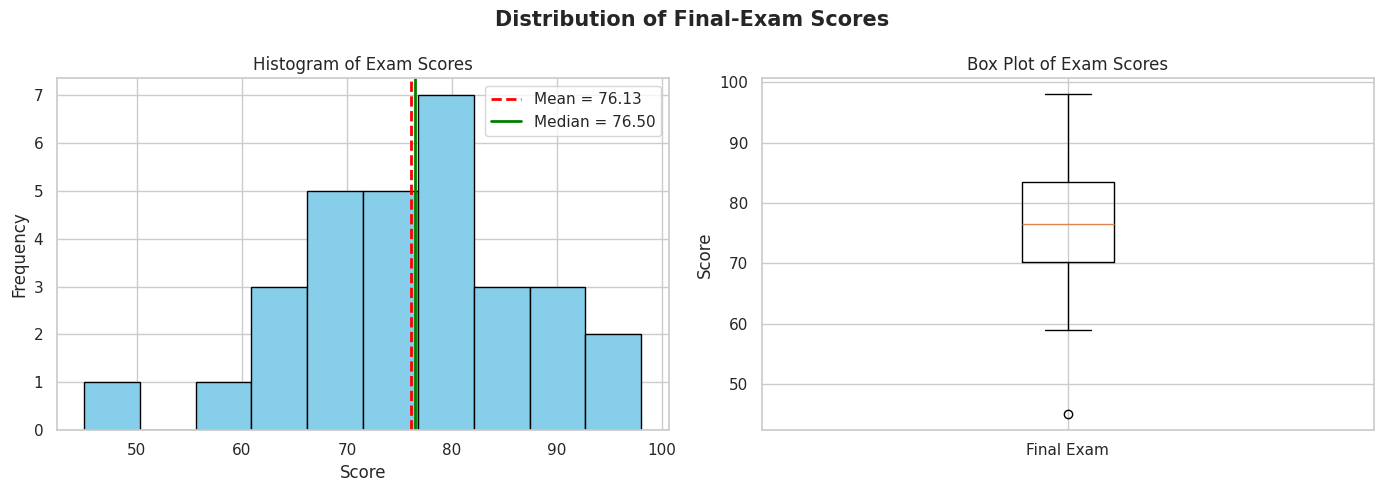

In [29]:
# Your Code
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mean_v = np.mean(scores)
median_v = np.median(scores)

axes[0].hist(scores, bins=10, color='skyblue', edgecolor='black')
axes[0].axvline(mean_v, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_v:.2f}')
axes[0].axvline(median_v, color='green', linestyle='-', linewidth=2, label=f'Median = {median_v:.2f}')
axes[0].set_title('Histogram of Exam Scores')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Frequency')
axes[0].legend()

axes[1].boxplot(scores)
axes[1].set_title('Box Plot of Exam Scores')
axes[1].set_ylabel('Score')
axes[1].set_xticklabels(['Final Exam'])

fig.suptitle('Distribution of Final-Exam Scores', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

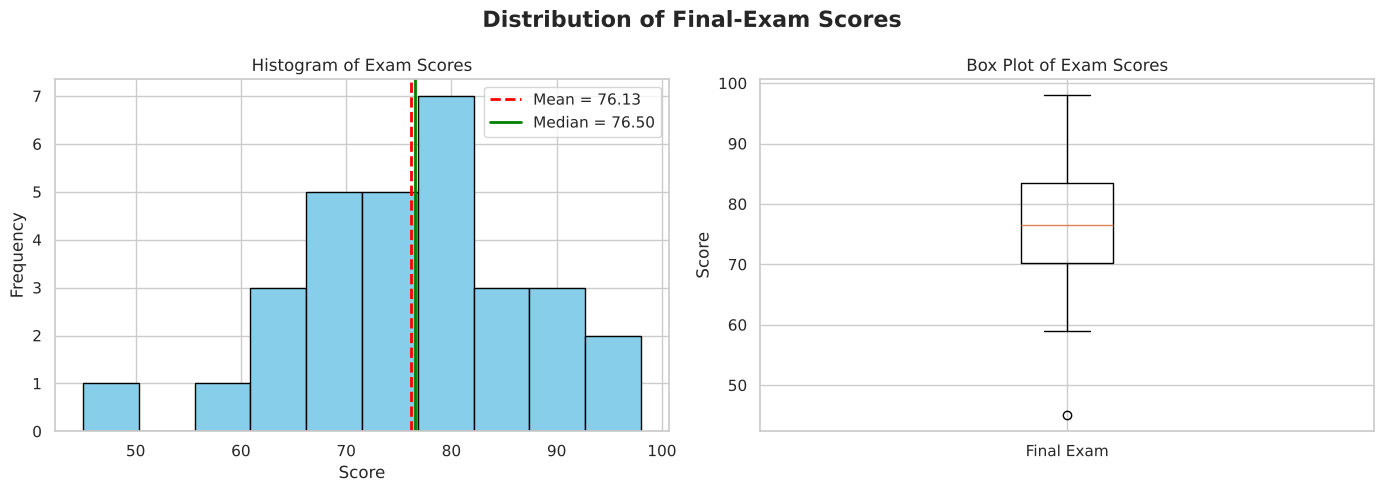

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The distribution is roughly symmetric. The mean (76.13) and median (76.50) are almost the same, and the histogram peaks in the middle. There is a very slight pull to the left from the low score of 45. In the box plot, the 45 appears as a lone circle below the lower whisker, which shows it is an outlier.

### Exercise A3 — Comparing Two Distributions (2 points)
Two sections took the same quiz:

```python
section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]
```
1. Use the **Shapiro-Wilk test** to check whether each section follows a normal distribution (α = 0.05).
2. Use **Student's t-test** (`ttest_ind`) and the **Mann-Whitney U test** (`mannwhitneyu`) to check whether the two sections have equal means. Print each p-value and the decision (reject / fail to reject H₀).
3. Draw **side-by-side box plots** of the two sections with a title and labelled ticks.

Based on the tests **and** the box plots, are the two sections similar? Explain why the box plot tells you something the t-test does not.

Shapiro-Wilk Section 1: p-value = 0.9911 -> Fail to reject H0
Shapiro-Wilk Section 2: p-value = 0.0101 -> Reject H0

Student's t-test     : p-value = 0.7468 -> Fail to reject H0
Mann-Whitney U test  : p-value = 0.6274 -> Fail to reject H0



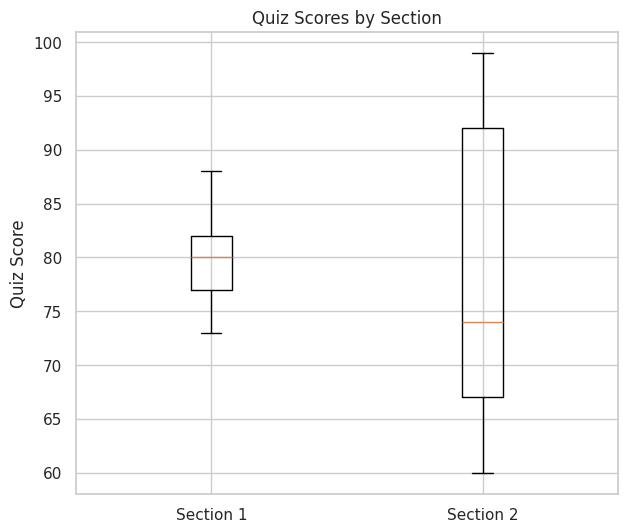

In [30]:
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]

# Your Code
for name, sec in [('Section 1', section_1), ('Section 2', section_2)]:
    p = shapiro(sec).pvalue
    print(f"Shapiro-Wilk {name}: p-value = {p:.4f} -> {'Reject H0' if p < 0.05 else 'Fail to reject H0'}")
print()
p_t = ttest_ind(section_1, section_2).pvalue
p_u = mannwhitneyu(section_1, section_2).pvalue
print(f"Student's t-test     : p-value = {p_t:.4f} -> {'Reject H0' if p_t < 0.05 else 'Fail to reject H0'}")
print(f"Mann-Whitney U test  : p-value = {p_u:.4f} -> {'Reject H0' if p_u < 0.05 else 'Fail to reject H0'}")
print()

plt.figure(figsize=(7, 6))
plt.boxplot([section_1, section_2])
plt.xticks([1, 2], ['Section 1', 'Section 2'])
plt.title('Quiz Scores by Section')
plt.ylabel('Quiz Score')
plt.show()

Shapiro-Wilk Section 1: p-value = 0.9911 -> Fail to reject H0
Shapiro-Wilk Section 2: p-value = 0.0101 -> Reject H0

Student's t-test     : p-value = 0.7468 -> Fail to reject H0
Mann-Whitney U test  : p-value = 0.6274 -> Fail to reject H0


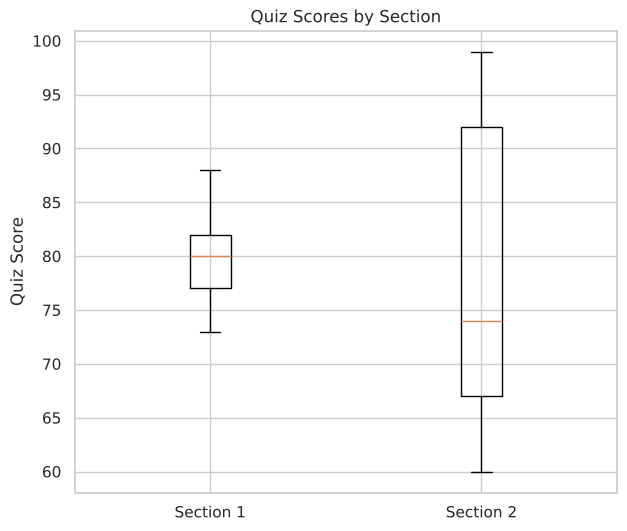

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: oth tests fail to reject equal means (p = 0.7468 and 0.6274), so the averages are similar. The two sections are not similar overall. Section 1 is tightly grouped around 80, roughly 73 to 88. Section 2 is spread from 60 to 99 and fails the normality test (p = 0.0101). The t-test only compares means, so it can’t see the difference in spread. The box plot shows it: Section 2’s box and whiskers are far wider.

---
## Part B — Data Cleaning and Preparation

### Exercise B1 — Cleaning a Messy Dataset (3 points)
The DataFrame below was collected by several people and contains typical data problems. Clean it by applying the following steps **in order**, then display the cleaned DataFrame:

1. **Remove duplicate** rows.
2. **Fix structural errors** in `City`: remove extra spaces and use title case (e.g. `' riyadh'` → `'Riyadh'`).
3. **Filter noisy data:** an age cannot be negative, so replace negative `Age` values with their absolute value.
4. **Wrangle inconsistent units:** some `Attendance` values were entered as fractions (e.g. `0.95`) instead of percentages. Convert any value ≤ 1 to a percentage.
5. **Standardize units:** create `Height_cm` from `Height_in` (1 in = 2.54 cm, rounded to 1 decimal) and **drop** `Height_in` (irrelevant once converted).
6. **Handle missing values:** fill `Age` with the **mean** (rounded to 0 decimals), `GPA` with the **median**, and `City` with the **mode**.
7. Reset the index (`drop=True`) and display the result.

In [31]:
data = {
    'Student':    ['Ali', 'Sara', 'Omar', 'Sara', 'Huda', 'Khalid', 'Mona', 'Yousef', 'Lina', 'Faisal'],
    'City':       ['Riyadh', ' riyadh', 'Jeddah', ' riyadh', 'DAMMAM', 'Jeddah ', 'riyadh', ' Riyadh', None, 'jeddah'],
    'Age':        [21, 22, np.nan, 22, 20, 23, -21, 24, 22, 21],
    'Height_in':  [70, 64, 68, 64, 62, 72, 61, 69, 63, 71],
    'GPA':        [3.2, 3.8, 2.9, 3.8, 3.5, np.nan, 3.6, 2.7, 3.9, 3.1],
    'Attendance': [0.95, 92, 88, 92, 97, 85, 90, 0.78, 99, 91]
}
df = pd.DataFrame(data)
display(df)

# Your Code
df = df.drop_duplicates()
df['City'] = df['City'].str.strip().str.title()
df['Age'] = df['Age'].abs()
df.loc[df['Attendance'] <= 1, 'Attendance'] *= 100
df['Height_cm'] = (df['Height_in'] * 2.54).round(1)
df = df.drop(columns='Height_in')
df['Age'] = df['Age'].fillna(round(df['Age'].mean()))
df['GPA'] = df['GPA'].fillna(df['GPA'].median())
df['City'] = df['City'].fillna(df['City'].mode()[0])
df = df.reset_index(drop=True)
display(df)


,Student,City,Age,Height_in,GPA,Attendance
0,Ali,Riyadh,21.0,70,3.2,0.95
1,Sara,riyadh,22.0,64,3.8,92.00
2,Omar,Jeddah,NaN,68,2.9,88.00
3,Sara,riyadh,22.0,64,3.8,92.00
4,Huda,DAMMAM,20.0,62,3.5,97.00
5,Khalid,Jeddah,23.0,72,NaN,85.00
6,Mona,riyadh,-21.0,61,3.6,90.00
7,Yousef,Riyadh,24.0,69,2.7,0.78
8,Lina,None,22.0,63,3.9,99.00
9,Faisal,jeddah,21.0,71,3.1,91.00


,Student,City,Age,GPA,Attendance,Height_cm
0,Ali,Riyadh,21.0,3.20,95.0,177.8
1,Sara,Riyadh,22.0,3.80,92.0,162.6
2,Omar,Jeddah,22.0,2.90,88.0,172.7
3,Huda,Dammam,20.0,3.50,97.0,157.5
4,Khalid,Jeddah,23.0,3.35,85.0,182.9
5,Mona,Riyadh,21.0,3.60,90.0,154.9
6,Yousef,Riyadh,24.0,2.70,78.0,175.3
7,Lina,Riyadh,22.0,3.90,99.0,160.0
8,Faisal,Jeddah,21.0,3.10,91.0,180.3


In [ ]:
# The output generated by the code written to answer this question should be as follows:

,Student,City,Age,Height_in,GPA,Attendance
0,Ali,Riyadh,21.0,70,3.2,0.95
1,Sara,riyadh,22.0,64,3.8,92.00
2,Omar,Jeddah,NaN,68,2.9,88.00
3,Sara,riyadh,22.0,64,3.8,92.00
4,Huda,DAMMAM,20.0,62,3.5,97.00
5,Khalid,Jeddah,23.0,72,NaN,85.00
6,Mona,riyadh,-21.0,61,3.6,90.00
7,Yousef,Riyadh,24.0,69,2.7,0.78
8,Lina,NaN,22.0,63,3.9,99.00
9,Faisal,jeddah,21.0,71,3.1,91.00


,Student,City,Age,GPA,Attendance,Height_cm
0,Ali,Riyadh,21.0,3.20,95.0,177.8
1,Sara,Riyadh,22.0,3.80,92.0,162.6
2,Omar,Jeddah,22.0,2.90,88.0,172.7
3,Huda,Dammam,20.0,3.50,97.0,157.5
4,Khalid,Jeddah,23.0,3.35,85.0,182.9
5,Mona,Riyadh,21.0,3.60,90.0,154.9
6,Yousef,Riyadh,24.0,2.70,78.0,175.3
7,Lina,Riyadh,22.0,3.90,99.0,160.0
8,Faisal,Jeddah,21.0,3.10,91.0,180.3


### Exercise B2 — Detecting and Treating Outliers (2 points)
The cell below generates 200 apartment prices (in SAR 1000s) plus a few extreme values.
1. Use the **IQR method** to compute the lower and upper bounds and print **how many outliers** there are.
2. Treat the outliers by **capping (winsorization)** at the **5th and 95th percentiles** (`np.clip`). Print the new min and max.
3. Draw **two box plots side by side** (1 × 2 subplots): *Before capping* and *After capping*. Add titles and a y-label.

Lower bound = 167.85, Upper bound = 540.65
Number of outliers: 4
After capping: min = 258.23, max = 465.26



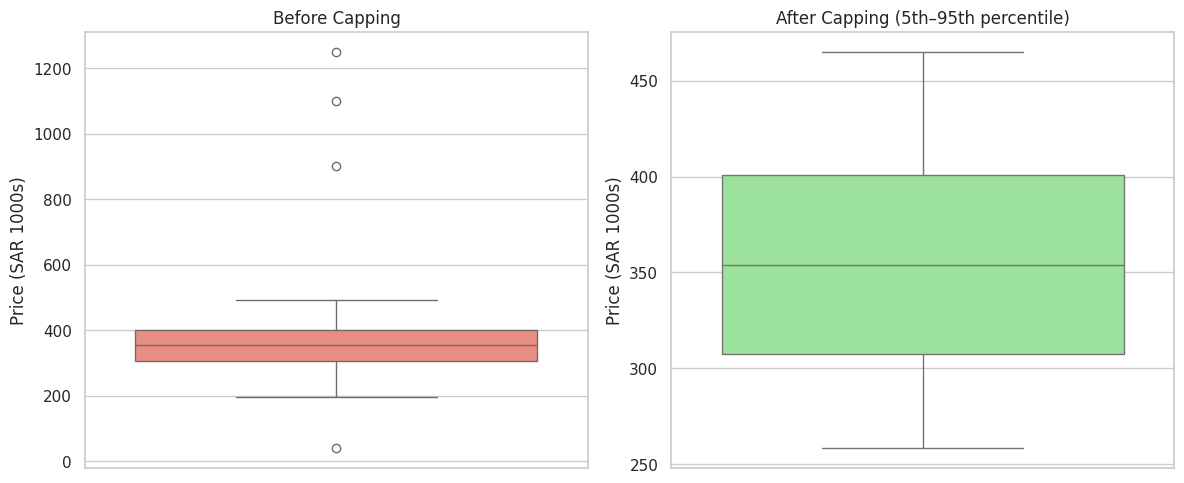

In [32]:
np.random.seed(0)
prices = np.concatenate([np.random.normal(350, 60, 200), [900, 1100, 40, 1250]])

# Your Code
q1, q3 = np.percentile(prices, [25, 75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
n_out = ((prices < lower) | (prices > upper)).sum()
print(f"Lower bound = {lower:.2f}, Upper bound = {upper:.2f}")
print("Number of outliers:", n_out)

p5, p95 = np.percentile(prices, [5, 95])
capped = np.clip(prices, p5, p95)
print(f"After capping: min = {capped.min():.2f}, max = {capped.max():.2f}")
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=prices, ax=axes[0], color='salmon')
axes[0].set_title('Before Capping')
axes[0].set_ylabel('Price (SAR 1000s)')
sns.boxplot(y=capped, ax=axes[1], color='lightgreen')
axes[1].set_title('After Capping (5th\u201395th percentile)')
axes[1].set_ylabel('Price (SAR 1000s)')
plt.tight_layout()
plt.show()


Lower bound = 167.85, Upper bound = 540.65
Number of outliers: 4
After capping: min = 258.23, max = 465.26


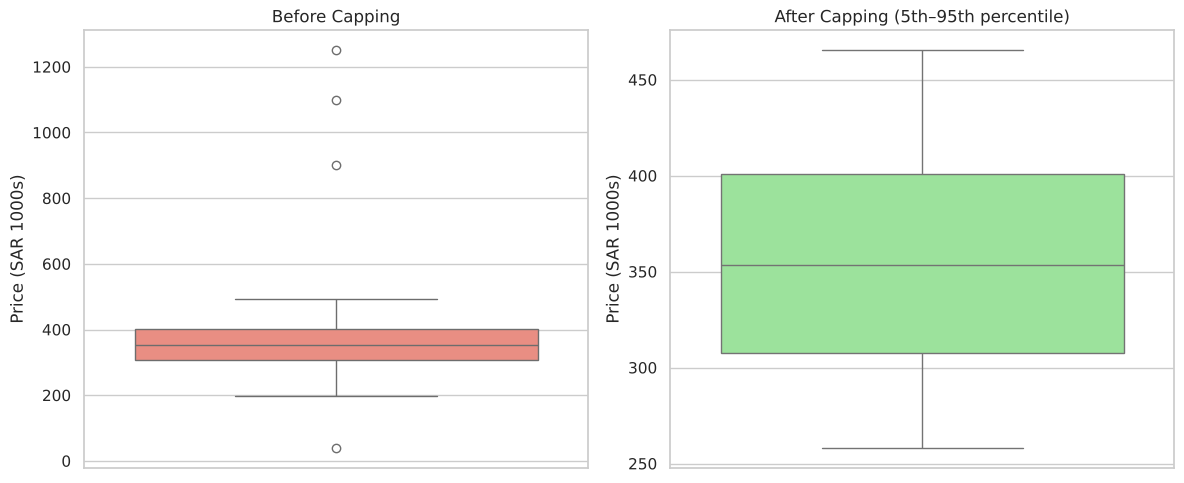

In [ ]:
# The output generated by the code written to answer this question should be as follows:

### Exercise B3 — Data Transformation (2 points)
The cell below generates 500 right-skewed household incomes. Create three new versions of the data:
- **Normalized** to the range [0, 1] using `MinMaxScaler`
- **Standardized** (mean 0, std 1) using `StandardScaler`
- **Log-transformed** using `np.log`

Plot the **four** versions (original + three transformed) as histograms in a **2 × 2 subplot grid** with 30 bins each, a title on every subplot, and an overall title.

Which transformation changes the **shape** of the distribution, and which ones only change the **scale**?

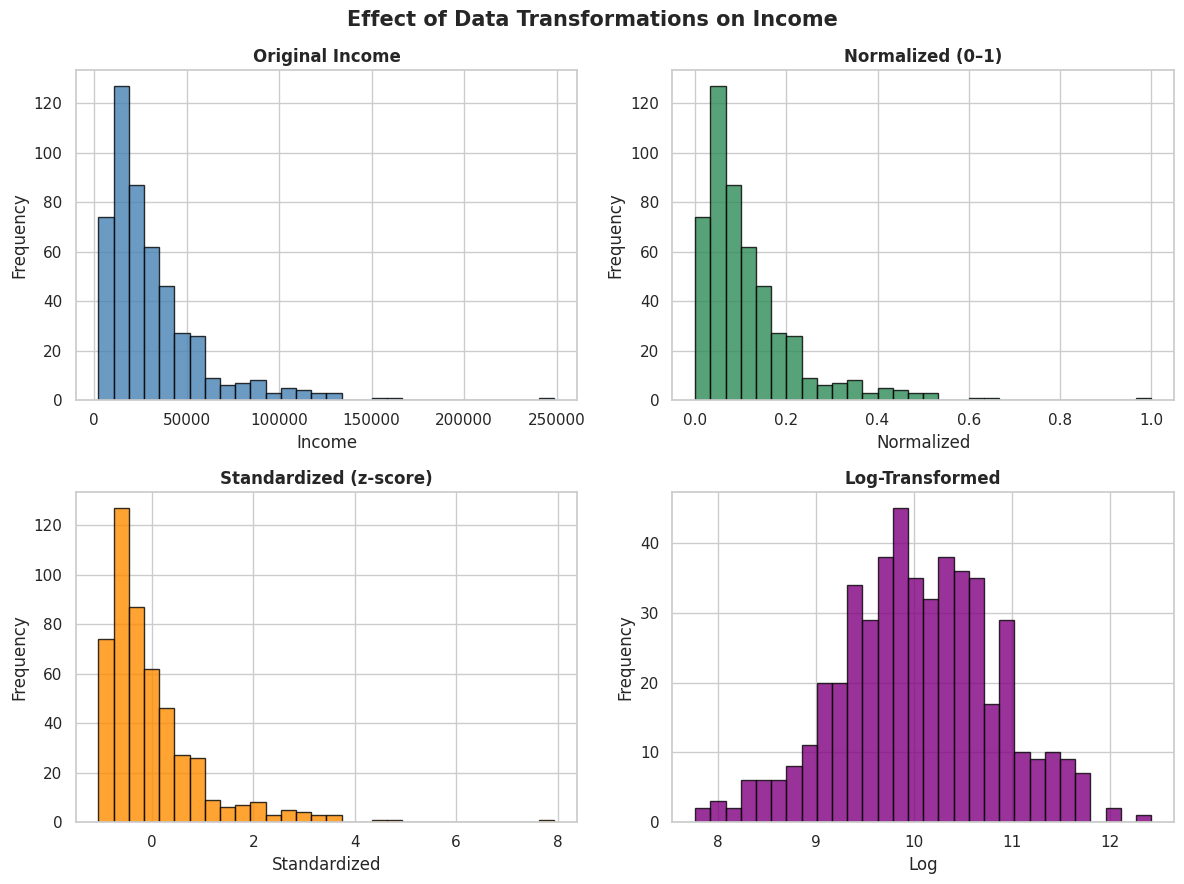

In [33]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

np.random.seed(1)
income = pd.DataFrame({'Income': np.random.lognormal(mean=10, sigma=0.8, size=500)})

# Your Code
normalized = MinMaxScaler().fit_transform(income[['Income']])
standardized = StandardScaler().fit_transform(income[['Income']])
logged = np.log(income['Income'])

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].hist(income['Income'], bins=30, color='steelblue', edgecolor='black', alpha=0.8)
axes[0, 0].set_title('Original Income', fontweight='bold')
axes[0, 0].set_xlabel('Income')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].hist(normalized, bins=30, color='seagreen', edgecolor='black', alpha=0.8)
axes[0, 1].set_title('Normalized (0\u20131)', fontweight='bold')
axes[0, 1].set_xlabel('Normalized')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].hist(standardized, bins=30, color='darkorange', edgecolor='black', alpha=0.8)
axes[1, 0].set_title('Standardized (z-score)', fontweight='bold')
axes[1, 0].set_xlabel('Standardized')
axes[1, 0].set_ylabel('Frequency')

axes[1, 1].hist(logged, bins=30, color='purple', edgecolor='black', alpha=0.8)
axes[1, 1].set_title('Log-Transformed', fontweight='bold')
axes[1, 1].set_xlabel('Log')
axes[1, 1].set_ylabel('Frequency')

fig.suptitle('Effect of Data Transformations on Income', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

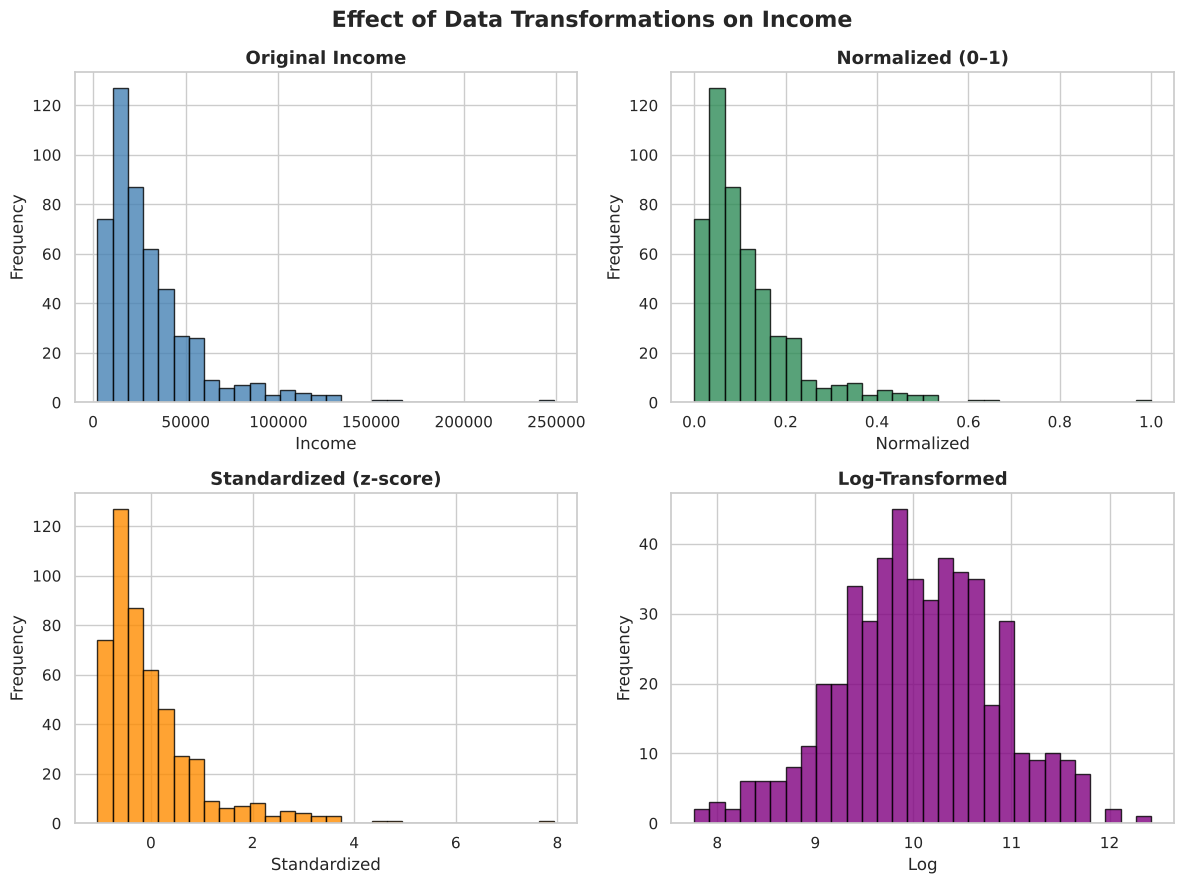

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: Only the log transform changes the shape. It turns the right-skewed income distribution into a roughly bell-shaped one. Normalization and standardization are linear transformations, so they only change the scale. The histogram keeps the same skewed shape, and only the x-axis values differ.

### Exercise B4 — Encoding Categorical Variables (2 points)
For the product table below:
1. `Size` is **ordinal**. Use a mapping dictionary to encode it as `Small → 1`, `Medium → 2`, `Large → 3`.
2. `In_Stock` is **binary**. Use `LabelEncoder` to encode it (`No → 0`, `Yes → 1`).
3. `Color` is **nominal**. Apply **one-hot encoding** with `pd.get_dummies` (`drop_first=True`, `dtype=int`).

Display the encoded DataFrame. Why is one-hot encoding (and not label encoding) the right choice for `Color`?

In [34]:
from sklearn.preprocessing import LabelEncoder

products = pd.DataFrame({
    'Product':  ['T-shirt', 'Jacket', 'Cap', 'Hoodie', 'Scarf', 'Jeans'],
    'Size':     ['Small', 'Large', 'Medium', 'Large', 'Small', 'Medium'],
    'Color':    ['Red', 'Blue', 'Green', 'Red', 'Green', 'Blue'],
    'In_Stock': ['Yes', 'No', 'Yes', 'Yes', 'No', 'Yes'],
    'Price':    [45, 220, 35, 150, 60, 180]
})
display(products)

# Your Code
products['Size'] = products['Size'].map({'Small': 1, 'Medium': 2, 'Large': 3})
products['In_Stock'] = LabelEncoder().fit_transform(products['In_Stock'])
products = pd.get_dummies(products, columns=['Color'], drop_first=True, dtype=int)
display(products)

,Product,Size,Color,In_Stock,Price
0,T-shirt,Small,Red,Yes,45
1,Jacket,Large,Blue,No,220
2,Cap,Medium,Green,Yes,35
3,Hoodie,Large,Red,Yes,150
4,Scarf,Small,Green,No,60
5,Jeans,Medium,Blue,Yes,180


,Product,Size,In_Stock,Price,Color_Green,Color_Red
0,T-shirt,1,1,45,0,1
1,Jacket,3,0,220,0,0
2,Cap,2,1,35,1,0
3,Hoodie,3,1,150,0,1
4,Scarf,1,0,60,1,0
5,Jeans,2,1,180,0,0


In [ ]:
# The output generated by the code written to answer this question should be as follows:

,Product,Size,Color,In_Stock,Price
0,T-shirt,Small,Red,Yes,45
1,Jacket,Large,Blue,No,220
2,Cap,Medium,Green,Yes,35
3,Hoodie,Large,Red,Yes,150
4,Scarf,Small,Green,No,60
5,Jeans,Medium,Blue,Yes,180


,Product,Size,In_Stock,Price,Color_Green,Color_Red
0,T-shirt,1,1,45,0,1
1,Jacket,3,0,220,0,0
2,Cap,2,1,35,1,0
3,Hoodie,3,1,150,0,1
4,Scarf,1,0,60,1,0
5,Jeans,2,1,180,0,0


**Your Answer:**

_Double-click this cell and write your answer here: Color is nominal, so its categories have no natural order. Label encoding would give Blue, Green and Red numbers like 0, 1 and 2, and a model would treat them as ordered with equal gaps (Red “greater than” Blue). One-hot encoding gives each color its own 0/1 column, so no false ranking is introduced.

---
## Part C — Advanced Plotting with Matplotlib & Seaborn (Penguins Dataset)

Load the built-in `penguins` dataset and drop the rows with missing values:
```python
penguins = sns.load_dataset('penguins').dropna()
```

### Exercise C1 — Subplots: Combining Matplotlib and Seaborn (2 points)
Create a **2 × 2 grid of subplots** (`figsize=(14, 10)`) and draw a **Seaborn** plot in each panel using the `ax=` argument:
- **[0, 0]** Histogram of `flipper_length_mm` with 20 bins and a KDE curve
- **[0, 1]** Scatter plot of `bill_length_mm` (x) vs `bill_depth_mm` (y), colored by `species`
- **[1, 0]** Bar plot of the mean `body_mass_g` per `species`
- **[1, 1]** Box plot of `body_mass_g` per `species`, split by `sex` (`hue`)

Give each subplot its own title, add an overall title (`fig.suptitle`) and use `plt.tight_layout()`.

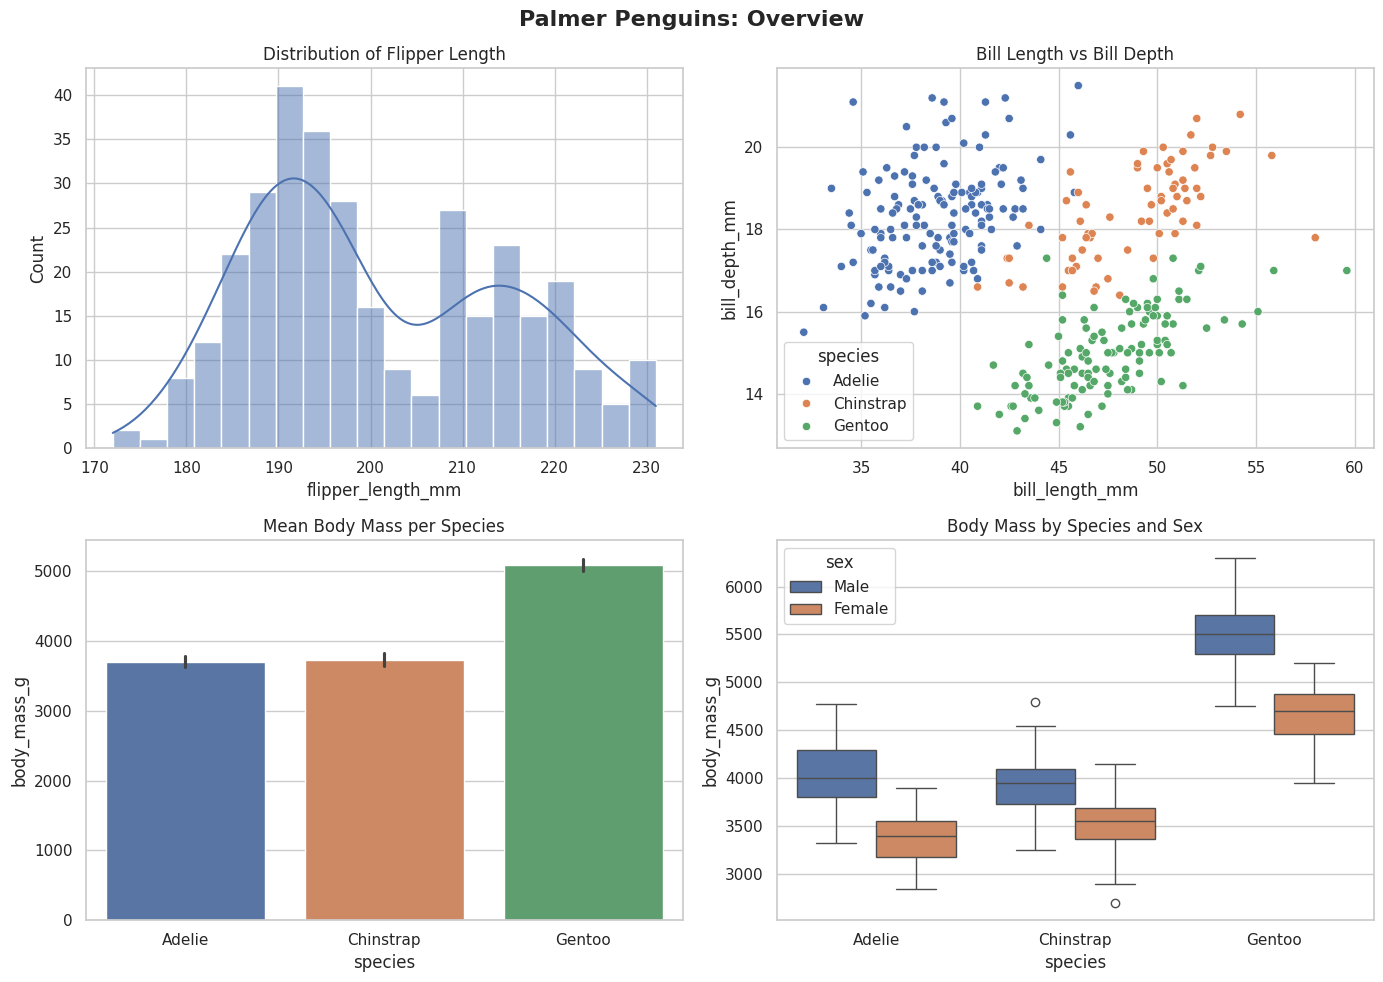

In [35]:
penguins = sns.load_dataset('penguins').dropna()

# Your Code
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=penguins, x='flipper_length_mm', bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Flipper Length')

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species', ax=axes[0, 1])
axes[0, 1].set_title('Bill Length vs Bill Depth')

sns.barplot(data=penguins, x='species', y='body_mass_g', hue='species', ax=axes[1, 0])
axes[1, 0].set_title('Mean Body Mass per Species')

sns.boxplot(data=penguins, x='species', y='body_mass_g', hue='sex', ax=axes[1, 1])
axes[1, 1].set_title('Body Mass by Species and Sex')

fig.suptitle('Palmer Penguins: Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

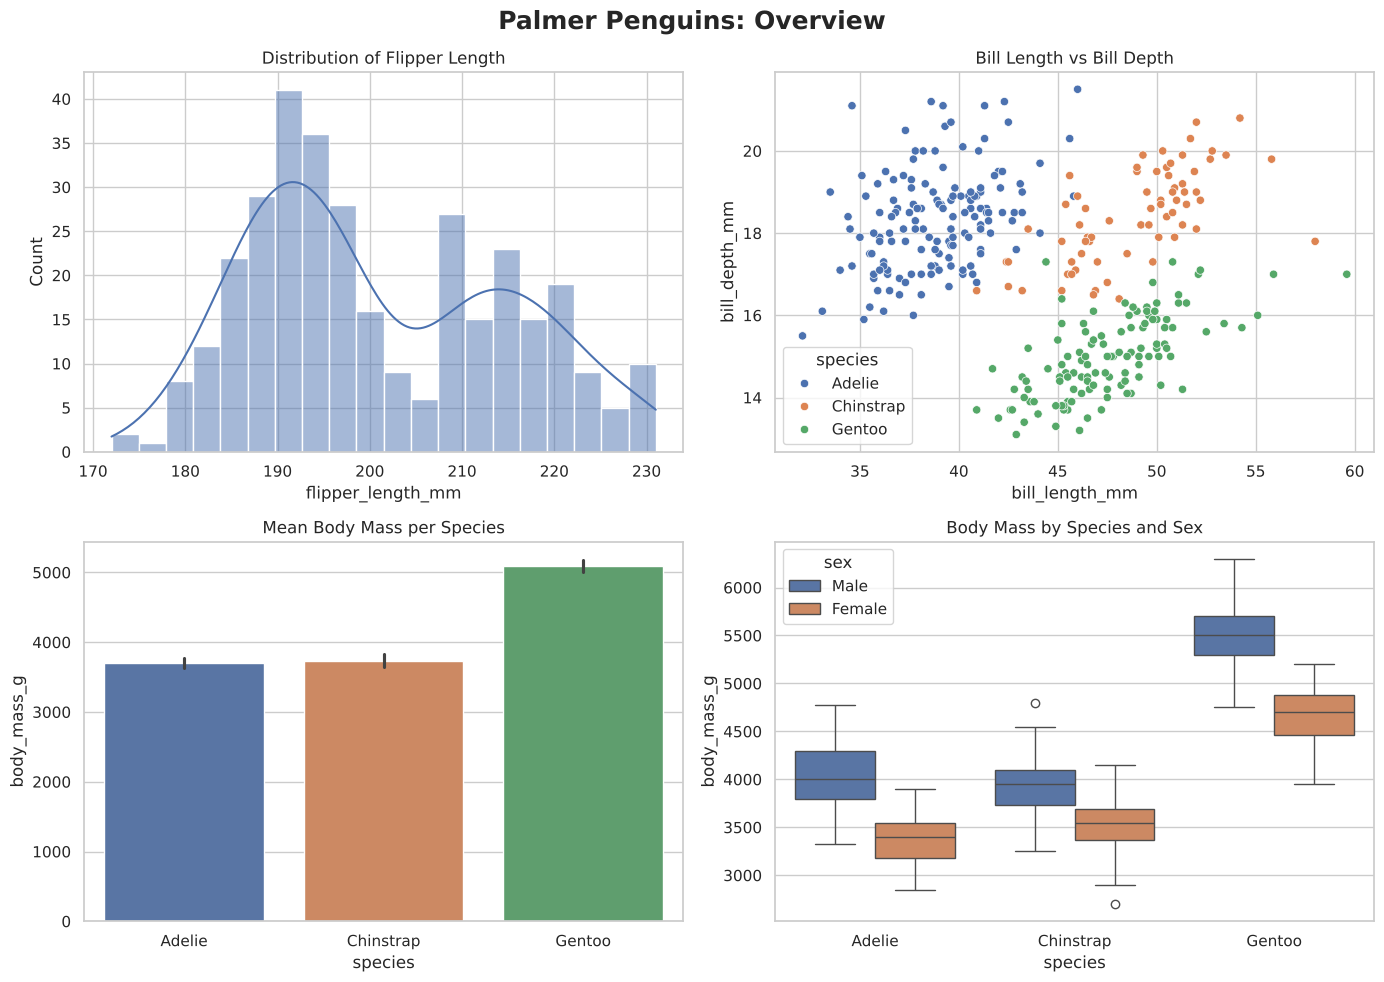

In [ ]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C2 — Correlation Heatmap (2 points)
Compute the **Pearson correlation matrix** of the four numeric columns of `penguins` and display it as a Seaborn **heatmap** with:
- the values annotated with 2 decimal places (`annot=True`, `fmt='.2f'`)
- the **diverging** colormap `'coolwarm'` with `vmin=-1`, `vmax=1`
- `linewidths=0.5` and a colorbar label `'Pearson r'`
- a title and `figsize=(8, 6)`

Which pair of variables has the **strongest positive** correlation, and which pair has the **strongest negative** correlation?

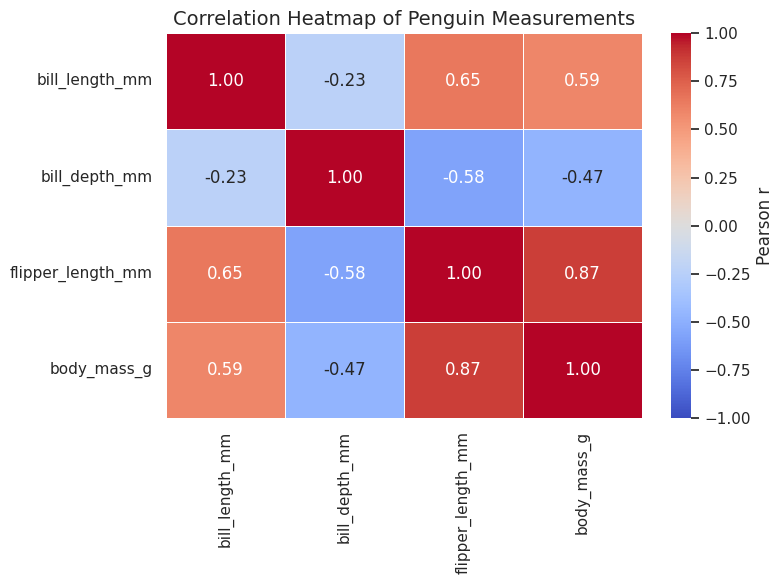

In [36]:
# Your Code
num_cols_c2 = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
corr = penguins[num_cols_c2].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Heatmap of Penguin Measurements', fontsize=14)
plt.tight_layout()
plt.show()

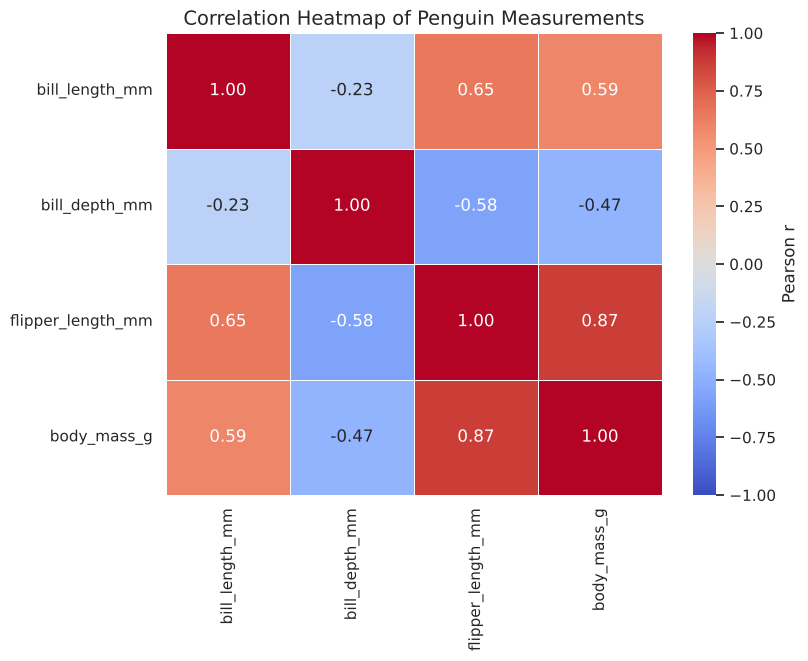

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: he strongest positive correlation is flipper_length_mm with body_mass_g (r = 0.87). The strongest negative is bill_depth_mm with flipper_length_mm (r = -0.58).

### Exercise C3 — Colormaps and Colorbars (2 points)
1. Using **Matplotlib** (`plt.scatter`), plot `flipper_length_mm` (x) vs `body_mass_g` (y), with the point colors given by `bill_length_mm` using the **sequential** colormap `'viridis'`. Add a **colorbar** labelled `'Bill Length (mm)'`, axis labels and a title.
2. In the **Your Answer** cell, state which **type of colormap** (sequential, diverging, cyclic or qualitative) you would use for each case, and name one example colormap for each:
   - (a) Temperature anomaly (°C above or below the long-term average)
   - (b) Population density of cities
   - (c) Wind direction (0°–360°)
   - (d) Blood type (A, B, AB, O)

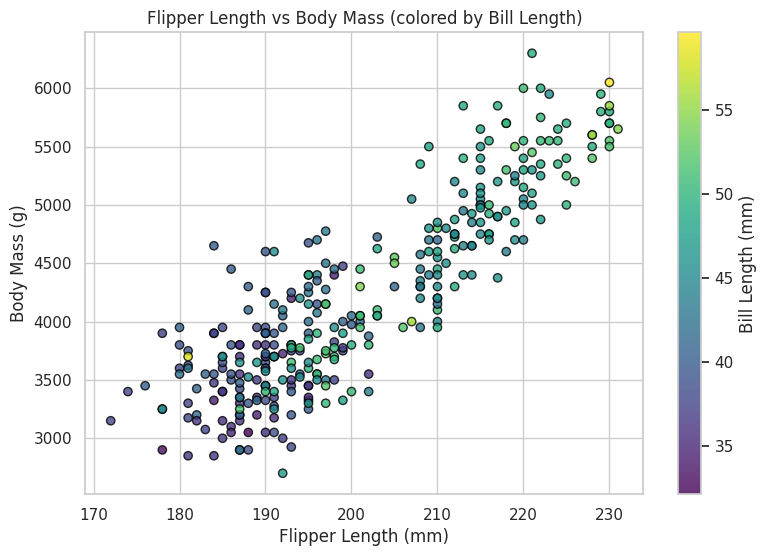

In [37]:
# Your Code
plt.figure(figsize=(9, 6))
sc = plt.scatter(penguins['flipper_length_mm'], penguins['body_mass_g'],
                 c=penguins['bill_length_mm'], cmap='viridis',
                 edgecolor='black', alpha=0.8)
plt.colorbar(sc, label='Bill Length (mm)')
plt.xlabel('Flipper Length (mm)', fontsize=12)
plt.ylabel('Body Mass (g)', fontsize=12)
plt.title('Flipper Length vs Body Mass (colored by Bill Length)', fontsize=12)
plt.show()

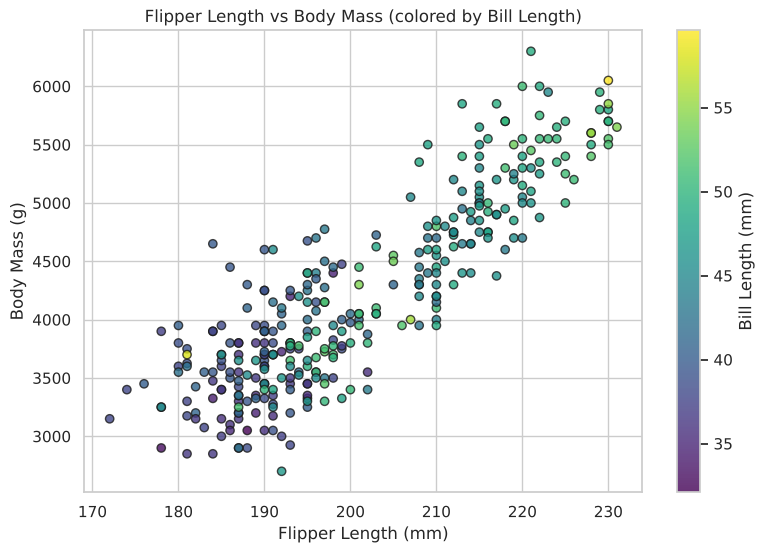

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: (a) Temperature anomaly: diverging, for example coolwarm or RdBu_r. The values go above and below a meaningful zero.
(b) Population density of cities: sequential, for example viridis or YlOrRd. It is an ordered low-to-high quantity.
(c) Wind direction (0°–360°): cyclic, for example twilight or hsv. 0° and 360° are the same direction, so the colors must wrap around.
(d) Blood type: qualitative, for example Set2 or tab10. The categories have no order.

### Exercise C4 — 3D Surface Plot and Contour Plot (2 points)
For the function $z = \sin\left(\sqrt{x^2 + y^2}\right)$ with $x, y \in [-6, 6]$ (use `np.linspace(-6, 6, 200)` and `np.meshgrid`), create **one figure** (`figsize=(15, 6)`) with two panels:
- **Left:** a **3D surface plot** (`projection='3d'`, `plot_surface`) using the colormap `'plasma'`
- **Right:** a **filled contour plot** (`contourf`, 20 levels, same colormap) with a **colorbar**

Label the x, y (and z) axes and give each panel a title.

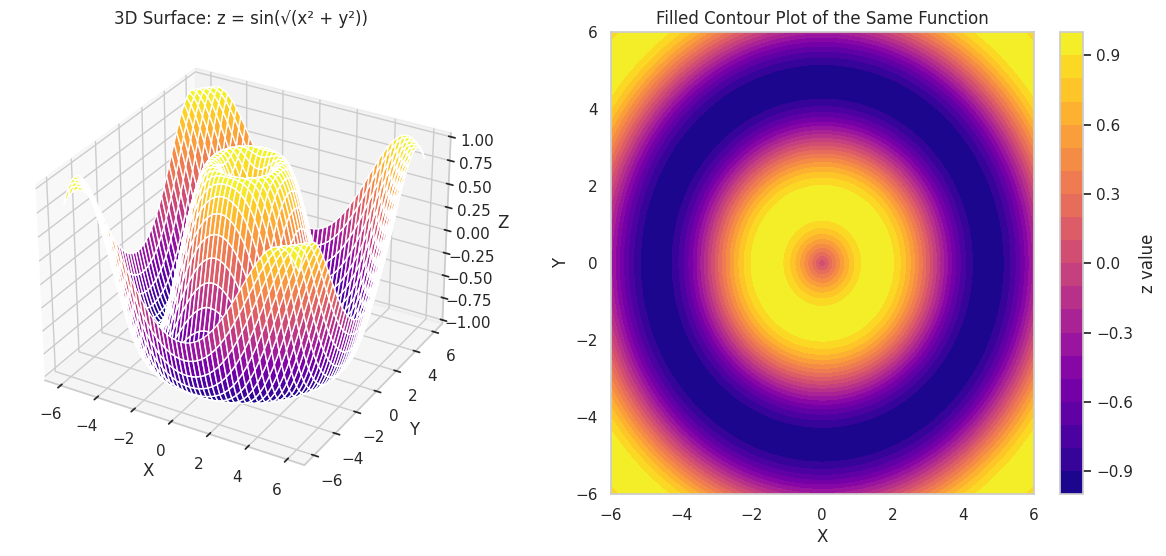

In [38]:
# Your Code
x = np.linspace(-6, 6, 200)
y = np.linspace(-6, 6, 200)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='plasma')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.set_title('3D Surface: z = sin(\u221a(x\u00b2 + y\u00b2))')

ax2 = fig.add_subplot(1, 2, 2)
cf = ax2.contourf(X, Y, Z, levels=20, cmap='plasma')
fig.colorbar(cf, ax=ax2, label='z value')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_title('Filled Contour Plot of the Same Function')
plt.show()

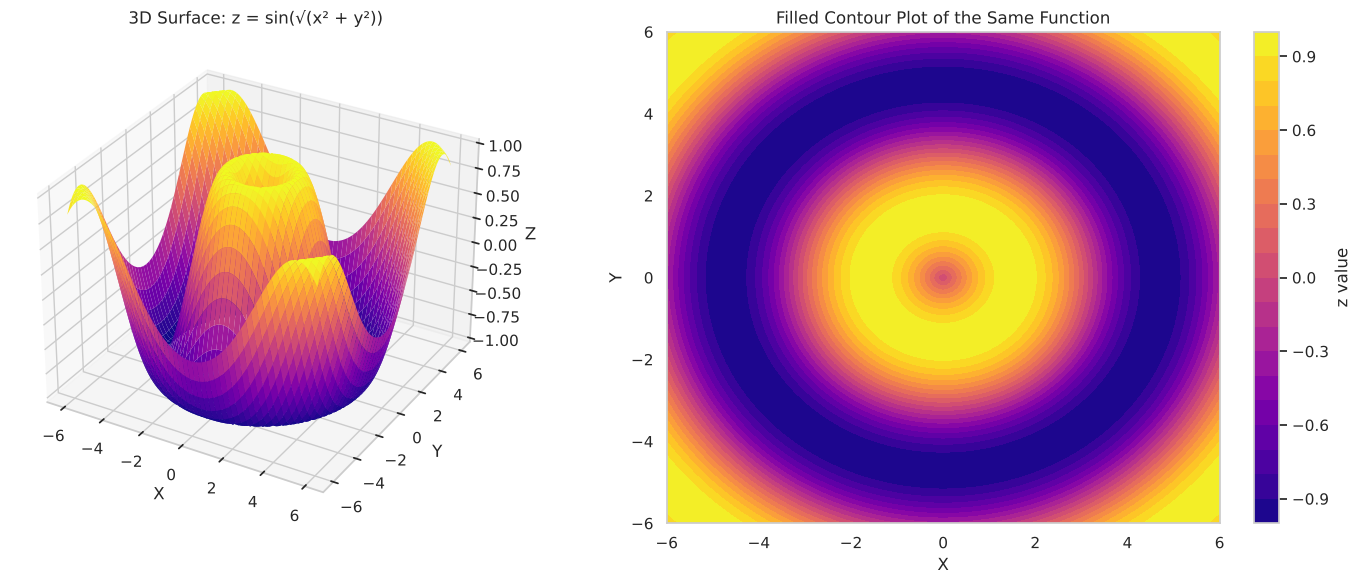

In [ ]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C5 — Customizing Labels, Fonts, Ticks and Legends (2 points)
Using the `flights` dataset, plot the monthly number of passengers for the years **1949**, **1954** and **1960** as three lines on the same axes (`figsize=(11, 6)`), with a different marker for each year. Then customize the plot:
- Title using `fontdict` with size **16**, **bold** and **italic**
- Axis labels with font size **13** and **bold** weight
- x-tick labels rotated **45°**
- Legend with the title `'Year'`, placed at `loc='upper left'`, `fontsize=11` and **no frame** (`frameon=False`)
- **Annotate** the peak month of 1960 with an arrow and the text `'Peak: <value>'` (look up `plt.annotate`)

*Hint:* `flights.pivot(index='month', columns='year', values='passengers')` gives one column per year.

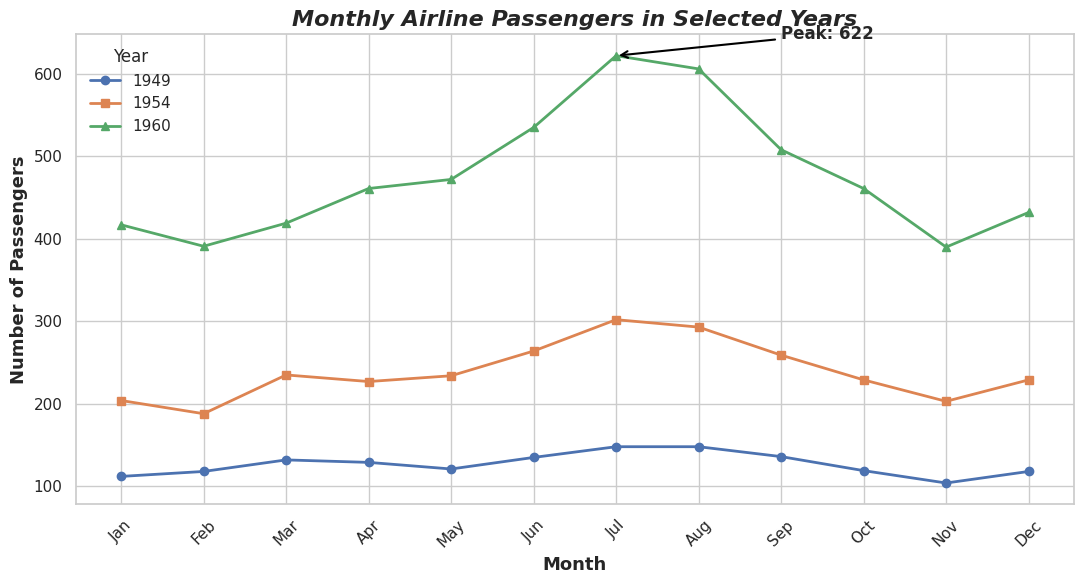

In [39]:
flights = sns.load_dataset('flights')

# Your Code
pv = flights.pivot(index='month', columns='year', values='passengers')
months = pv.index.astype(str)

plt.figure(figsize=(11, 6))
plt.plot(months, pv[1949], marker='o', linewidth=2, label='1949')
plt.plot(months, pv[1954], marker='s', linewidth=2, label='1954')
plt.plot(months, pv[1960], marker='^', linewidth=2, label='1960')

plt.title('Monthly Airline Passengers in Selected Years',
          fontdict={'fontsize': 16, 'fontweight': 'bold', 'fontstyle': 'italic'})
plt.xlabel('Month', fontsize=13, fontweight='bold')
plt.ylabel('Number of Passengers', fontsize=13, fontweight='bold')
plt.xticks(rotation=45)
plt.legend(title='Year', loc='upper left', fontsize=11, frameon=False)

peak_idx = int(np.argmax(pv[1960].values))
peak_val = pv[1960].max()
plt.annotate(f'Peak: {peak_val}', xy=(peak_idx, peak_val), xytext=(peak_idx + 2, peak_val + 20),
             fontsize=12, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
plt.tight_layout()
plt.show()

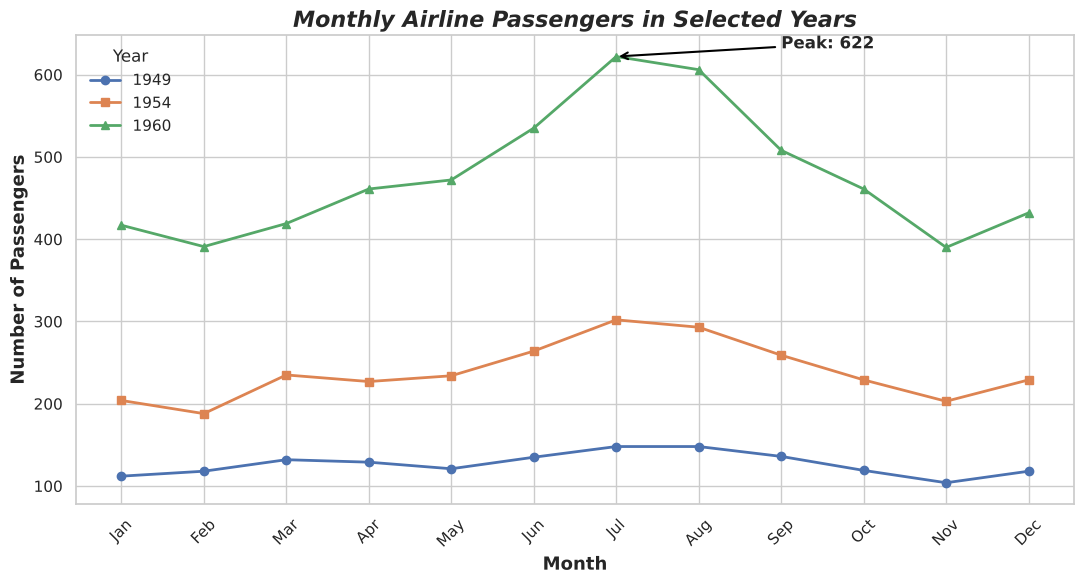

In [ ]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C6 — Network Graph (2 points)
Using `networkx`, build the **campus network topology** defined by the edges below and draw it with:
- `nx.spring_layout(G, seed=7)` for the node positions
- **node size proportional to the node's degree** (e.g. `300 + 400 * degree`)
- **node color based on degree** using the colormap `'YlOrRd'`
- node labels and a title

Print the degree of every node (sorted from highest to lowest). Which device is the **hub** of the network (highest degree)?

Switch A    : 5
Core Router : 4
Switch B    : 3
Switch C    : 3
Firewall    : 2
Web Server  : 2
DB Server   : 2
Internet    : 1
Lab PC 1    : 1
Lab PC 2    : 1
Lab PC 3    : 1
Printer     : 1
Office PC 1 : 1
Office PC 2 : 1


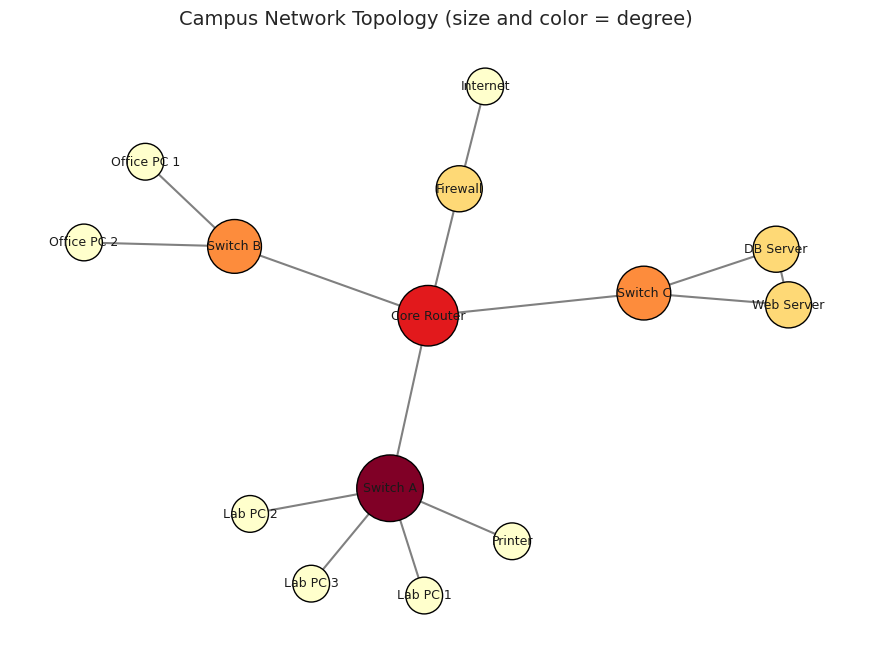

In [40]:
import networkx as nx

edges = [('Internet', 'Firewall'), ('Firewall', 'Core Router'),
         ('Core Router', 'Switch A'), ('Core Router', 'Switch B'), ('Core Router', 'Switch C'),
         ('Switch A', 'Lab PC 1'), ('Switch A', 'Lab PC 2'), ('Switch A', 'Lab PC 3'), ('Switch A', 'Printer'),
         ('Switch B', 'Office PC 1'), ('Switch B', 'Office PC 2'),
         ('Switch C', 'Web Server'), ('Switch C', 'DB Server'), ('Web Server', 'DB Server')]

# Your Code
G = nx.Graph()
G.add_edges_from(edges)

degrees = dict(G.degree())
for node, d in sorted(degrees.items(), key=lambda kv: kv[1], reverse=True):
    print(f"{node:<12}: {d}")

pos = nx.spring_layout(G, seed=7)
node_sizes = [300 + 400 * degrees[n] for n in G.nodes()]
node_colors = [degrees[n] for n in G.nodes()]

plt.figure(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, edge_color='gray', width=1.5)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors,
                       cmap='YlOrRd', edgecolors='black')
nx.draw_networkx_labels(G, pos, font_size=9)
plt.title('Campus Network Topology (size and color = degree)', fontsize=14)
plt.axis('off')
plt.show()

Switch A    : 5
Core Router : 4
Switch B    : 3
Switch C    : 3
Firewall    : 2
Web Server  : 2
DB Server   : 2
Internet    : 1
Lab PC 1    : 1
Lab PC 2    : 1
Lab PC 3    : 1
Printer     : 1
Office PC 1 : 1
Office PC 2 : 1


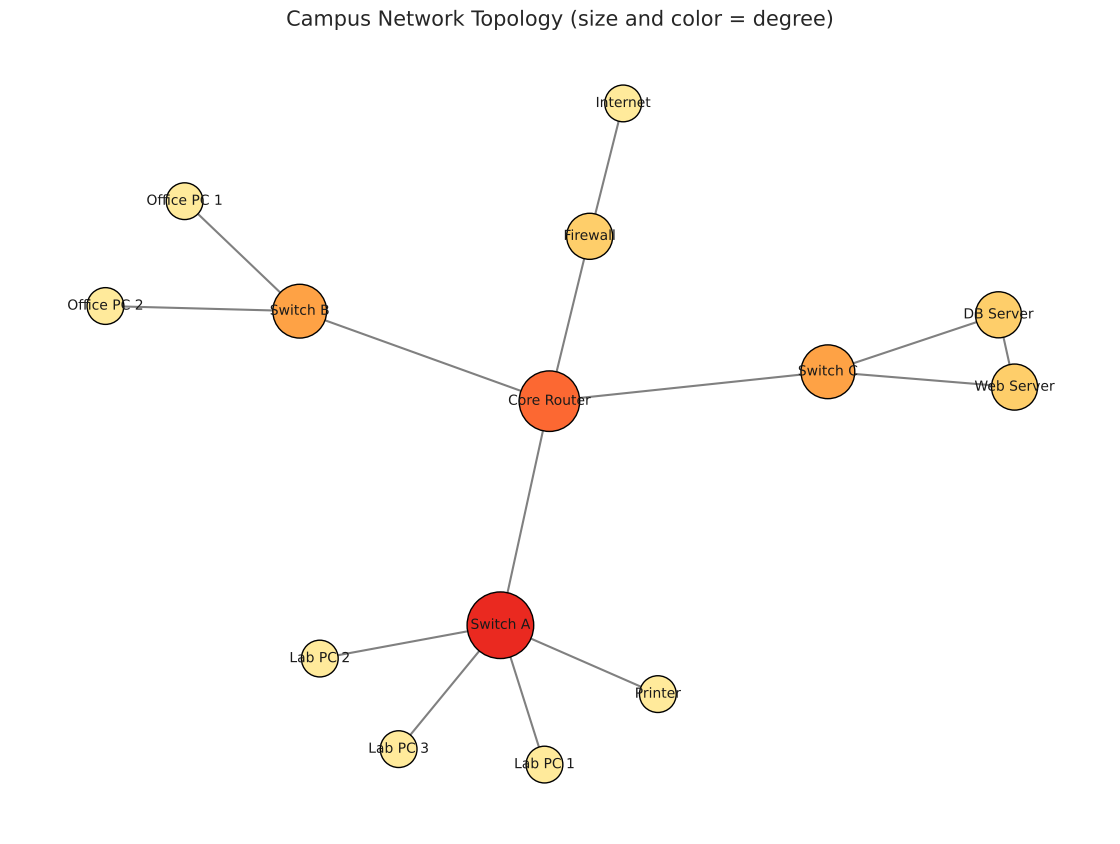

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The hub is Switch A, with degree 5 (Core Router is next with 4).

---
## Part D — Exploratory Data Analysis

### Exercise D1 — Pearson Correlation by Formula (2 points)
A store recorded its weekly advertising budget (SAR 1000s) and weekly sales (SAR 1000s):

```python
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]
```
1. Compute Pearson's *r* using the formula from the lecture:
$$r = \frac{N \sum xy-\sum x \sum y}{\sqrt{\left[N\sum x^2-\left(\sum x\right)^2\right]\left[N\sum y^2-\left(\sum y\right)^2\right]}}$$
   Print *r* (4 decimal places).
2. Verify your result with `df.corr(method='pearson')`.
3. Draw a scatter plot with a fitted regression line using `sns.regplot`.

Interpret the **strength** and **direction** of the relationship.

Pearson's r (formula): 0.9933

          ad_spend     sales
ad_spend  1.000000  0.993283
sales     0.993283  1.000000


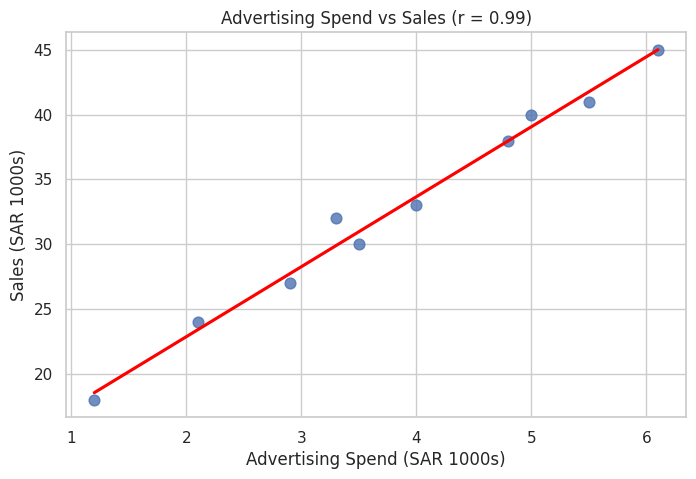

In [41]:
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]

# Your Code
N = len(ad_spend)
x = np.array(ad_spend)
y = np.array(sales)

num = N * np.sum(x * y) - np.sum(x) * np.sum(y)
den = np.sqrt((N * np.sum(x**2) - np.sum(x)**2) * (N * np.sum(y**2) - np.sum(y)**2))
r = num / den
print(f"Pearson's r (formula): {r:.4f}")
print()

store = pd.DataFrame({'ad_spend': ad_spend, 'sales': sales})
print(store.corr(method='pearson'))

plt.figure(figsize=(8, 5))
sns.regplot(data=store, x='ad_spend', y='sales', ci=None,
            scatter_kws={'s': 60, 'alpha': 0.8}, line_kws={'color': 'red'})
plt.title(f'Advertising Spend vs Sales (r = {r:.2f})')
plt.xlabel('Advertising Spend (SAR 1000s)', fontsize=12)
plt.ylabel('Sales (SAR 1000s)', fontsize=12)
plt.show()

Pearson's r (formula): 0.9933


,ad_spend,sales
ad_spend,1.000000,0.993283
sales,0.993283,1.000000


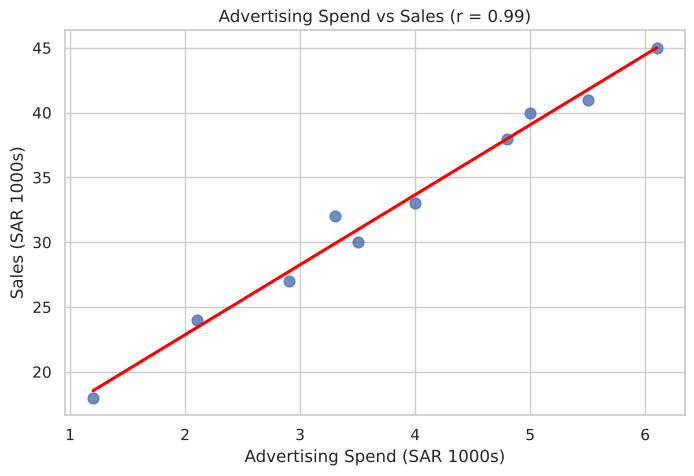

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: r = 0.9933, a very strong positive linear relationship. When advertising spend goes up, sales go up almost in a straight line. This shows association, not proof that advertising causes the sales.

### Exercise D2 — Principal Component Analysis (2 points)
Using the four numeric columns of `penguins`:
1. **Standardize** the features with `StandardScaler`.
2. Apply `PCA(n_components=2)` and add the two components to `penguins` as columns `pca1` and `pca2`.
3. Print the **variance captured** by each principal component, the total variance captured, and the **coefficients of PC1** (rounded to 3 decimals). Which original column has the largest absolute coefficient in PC1?
4. Draw a scatter plot of `pca1` vs `pca2`, colored by `species` (`hue`) with a different marker for each `sex` (`style`).

Can the first two principal components separate the three species?

Variance captured by PC1: 68.63%
Variance captured by PC2: 19.45%
Total variance captured: 88.09%

PC1 coefficients:
bill_length_mm       0.454
bill_depth_mm       -0.399
flipper_length_mm    0.577
body_mass_g          0.550
dtype: float64

Largest absolute coefficient in PC1: flipper_length_mm


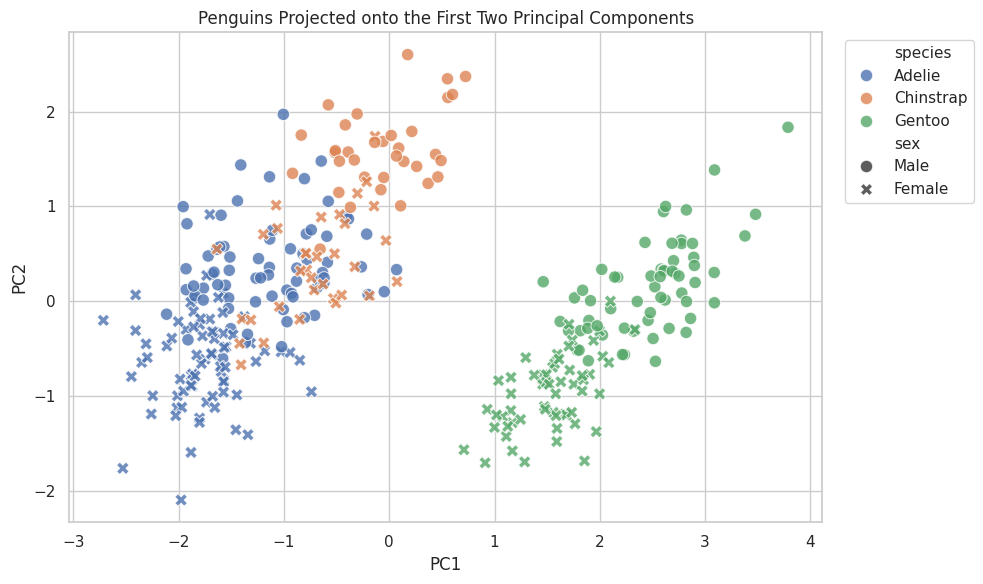

In [42]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Your Code
X_scaled = StandardScaler().fit_transform(penguins[num_cols])
pca = PCA(n_components=2)
comps = pca.fit_transform(X_scaled)
penguins['pca1'] = comps[:, 0]
penguins['pca2'] = comps[:, 1]

ev = pca.explained_variance_ratio_
print(f"Variance captured by PC1: {ev[0]*100:.2f}%")
print(f"Variance captured by PC2: {ev[1]*100:.2f}%")
print(f"Total variance captured: {ev.sum()*100:.2f}%")
print()
pc1 = pd.Series(pca.components_[0], index=num_cols).round(3)
print("PC1 coefficients:")
print(pc1)
print()
print("Largest absolute coefficient in PC1:", pc1.abs().idxmax())

plt.figure(figsize=(10, 6))
sns.scatterplot(data=penguins, x='pca1', y='pca2', hue='species', style='sex', s=80, alpha=0.8)
plt.title('Penguins Projected onto the First Two Principal Components')
plt.xlabel('PC1', fontsize=12)
plt.ylabel('PC2', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Variance captured by PC1: 68.63%
Variance captured by PC2: 19.45%
Total variance captured: 88.09%

PC1 coefficients:
bill_length_mm       0.454
bill_depth_mm       -0.399
flipper_length_mm    0.577
body_mass_g          0.550

Largest absolute coefficient in PC1: flipper_length_mm


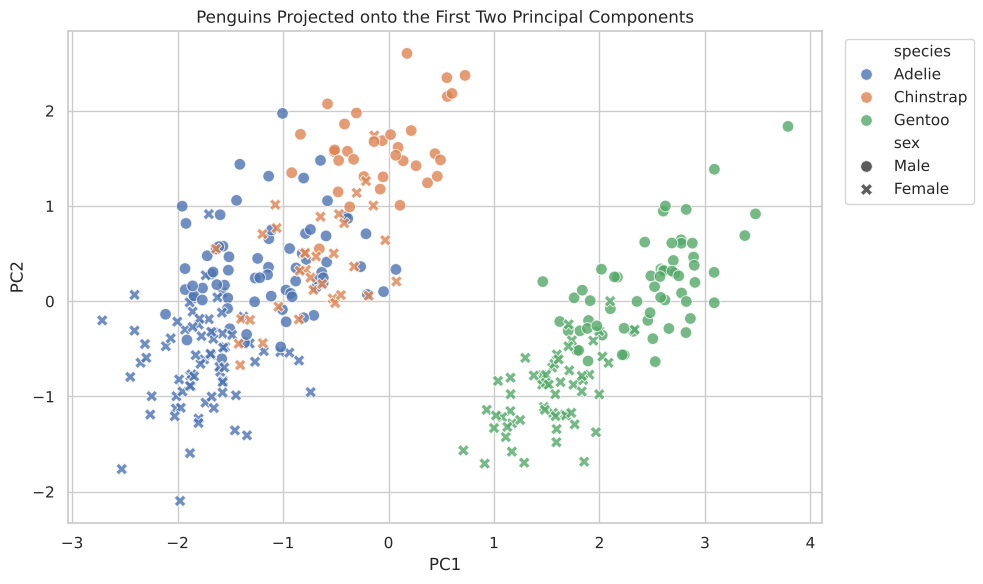

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The largest absolute coefficient in PC1 is flipper_length_mm (0.577). The first two components capture 88.09% of the variance. They separate Gentoo clearly from the other two species. Adelie and Chinstrap still overlap, so the three species are only partly separated.

### Exercise D3 — Cross Tables and Pivot Tables (2 points)
1. Create a **cross table** (`pd.crosstab`) showing the number of penguins of each `species` on each `island`, including row/column totals (`margins=True`).
2. Create a **pivot table** (`pd.pivot_table`) showing the **mean** `body_mass_g` for each `species` (rows) and `sex` (columns), rounded to 1 decimal.
3. Visualize the cross table from step 1 (without the totals) as a **heatmap** with annotated counts (`fmt='d'`, colormap `'Blues'`).

Which species lives on **all three** islands? Which island has only **one** species?

island     Biscoe  Dream  Torgersen  All
species                                 
Adelie         44     55         47  146
Chinstrap       0     68          0   68
Gentoo        119      0          0  119
All           163    123         47  333
sex        Female    Male
species                  
Adelie     3368.8  4043.5
Chinstrap  3527.2  3939.0
Gentoo     4679.7  5484.8


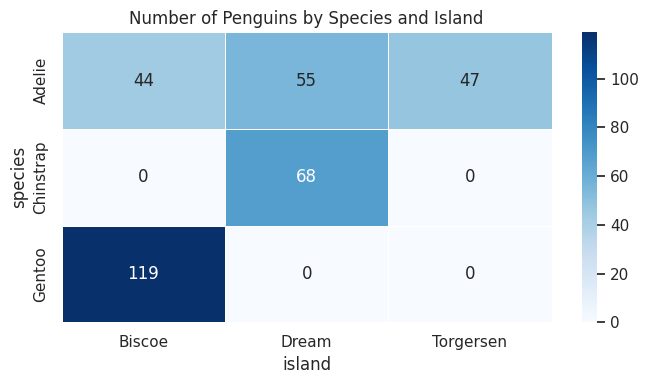

In [43]:
# Your Code
ct = pd.crosstab(penguins['species'], penguins['island'], margins=True)
print(ct)
pt = pd.pivot_table(penguins, values='body_mass_g', index='species', columns='sex', aggfunc='mean').round(1)
print(pt)

plt.figure(figsize=(7, 4))
sns.heatmap(ct.iloc[:-1, :-1], annot=True, fmt='d', cmap='Blues', linewidths=0.5)
plt.title('Number of Penguins by Species and Island')
plt.tight_layout()
plt.show()

island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,55,47,146
Chinstrap,0,68,0,68
Gentoo,119,0,0,119
All,163,123,47,333


sex,Female,Male
species,,
Adelie,3368.8,4043.5
Chinstrap,3527.2,3939.0
Gentoo,4679.7,5484.8


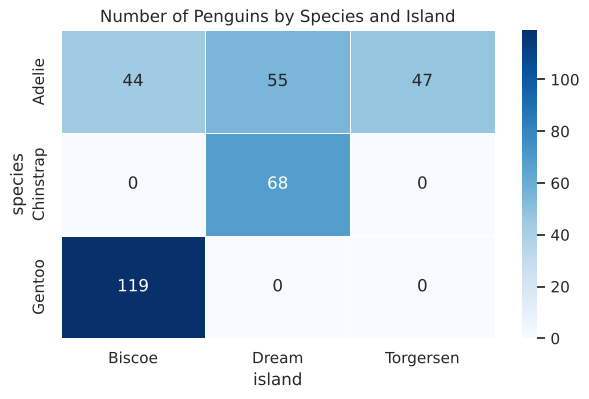

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: Adelie lives on all three islands (Biscoe, Dream and Torgersen). Torgersen has only one species, which is Adelie.

### Exercise D4 — Violin Plot (2 points)
Draw a Seaborn **violin plot** of `body_mass_g` (y) for each `island` (x), split by `sex` (`hue='sex'`, `split=True`) and showing the quartiles inside (`inner='quart'`). Add a title and axis labels.

What information does a violin plot show that a box plot does not?

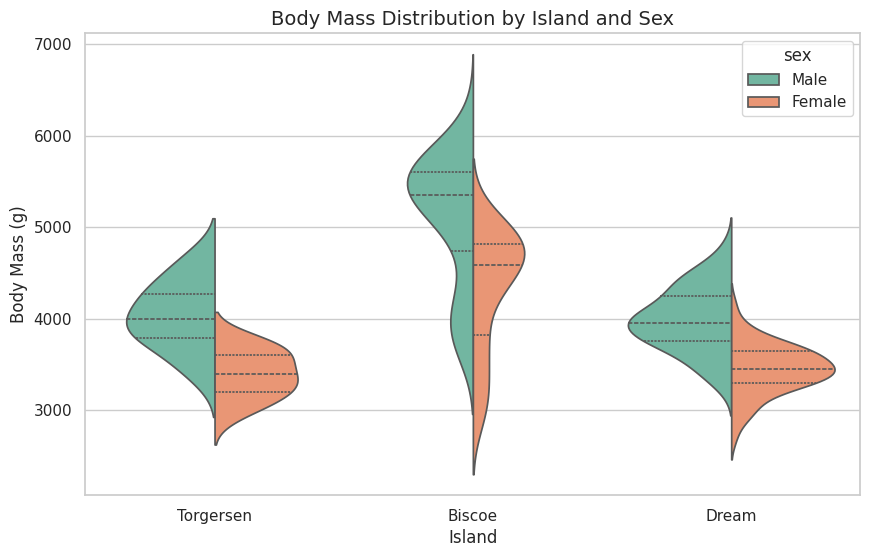

In [44]:
# Your Code
plt.figure(figsize=(10, 6))
sns.violinplot(data=penguins, x='island', y='body_mass_g', hue='sex',
               split=True, inner='quart', palette='Set2')
plt.title('Body Mass Distribution by Island and Sex', fontsize=14)
plt.xlabel('Island', fontsize=12)
plt.ylabel('Body Mass (g)', fontsize=12)
plt.show()

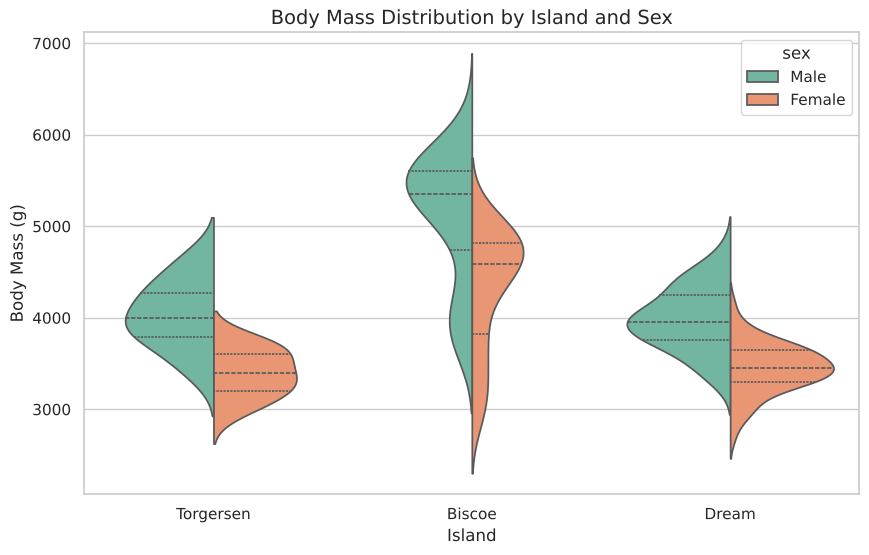

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: A violin plot shows the whole shape of the distribution (the density), not just the quartiles. It reveals things like several peaks. Biscoe’s body mass has a wide, uneven shape, which comes from mixing two species. A box plot reduces all of that to five numbers and hides the shape.

### Exercise D5 — Pair Plot (2 points)
Create a Seaborn **pair plot** of the four numeric measurement columns, colored by `species`, using `corner=True` and `diag_kind='kde'`. Add an overall title with `plt.suptitle(..., y=1.02)`.

Which **single** pair of variables best separates all three species?

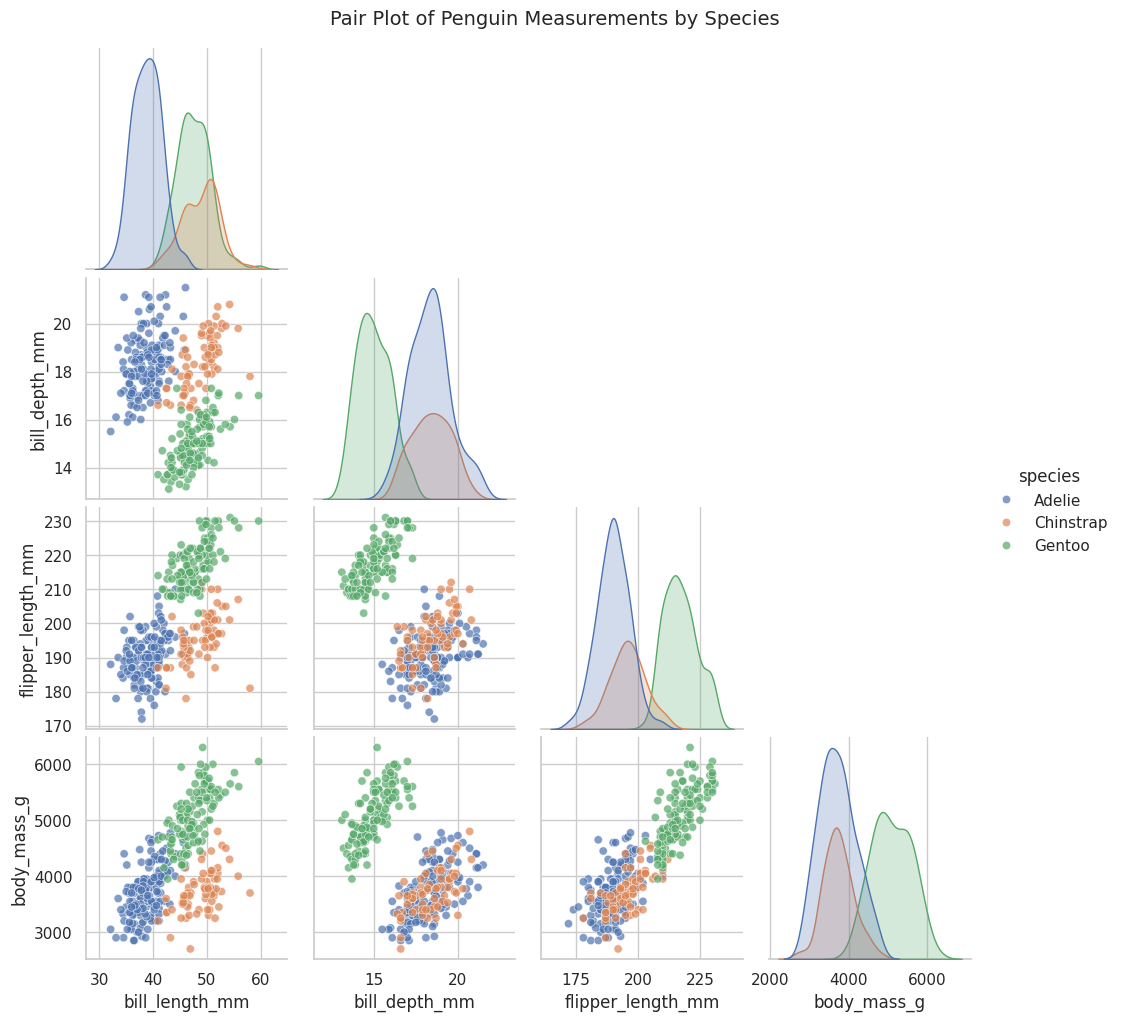

In [45]:
# Your Code
g = sns.pairplot(penguins[num_cols + ['species']], hue='species', corner=True,
                 diag_kind='kde', plot_kws={'alpha': 0.7})
plt.suptitle('Pair Plot of Penguin Measurements by Species', y=1.02, fontsize=14)
plt.show()

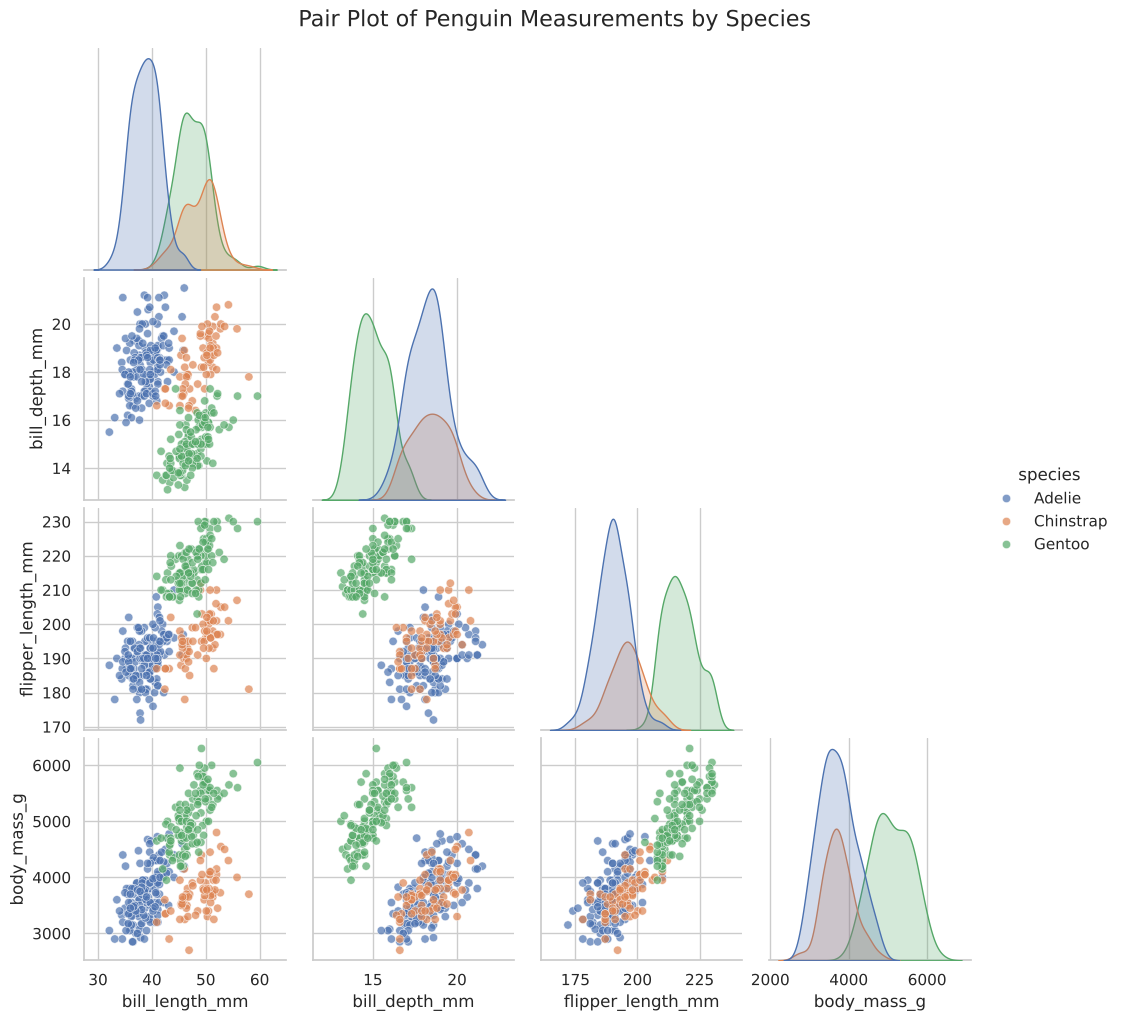

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: bill_length_mm vs bill_depth_mm best separates all three species. In that panel the three species form three distinct clusters. In most other pairs, Adelie and Chinstrap overlap.

---
## Part E — Visualizing and Analyzing Time Series Data (Flights Dataset)

Run the cell below to turn the `flights` dataset into a **monthly time series** `ts` with a `DatetimeIndex` (January 1949 to December 1960).

In [21]:
flights = sns.load_dataset('flights')
flights['date'] = pd.date_range(start='1949-01-01', periods=len(flights), freq='MS')
ts = flights.set_index('date')['passengers'].asfreq('MS')
ts.head()

,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


### Exercise E1 — Moving Averages and Smoothing (2 points)
On one figure (`figsize=(12, 6)`), plot:
- the original series `ts`
- its **12-month Simple Moving Average (SMA)** using `.rolling(window=12).mean()`
- its **12-month Exponential Moving Average (EMA)** using `.ewm(span=12, adjust=False).mean()`

Use different colors and line widths, and add a legend, axis labels and a title.

Why does the SMA line start 11 months later than the original data, and which of the two averages reacts faster to changes?

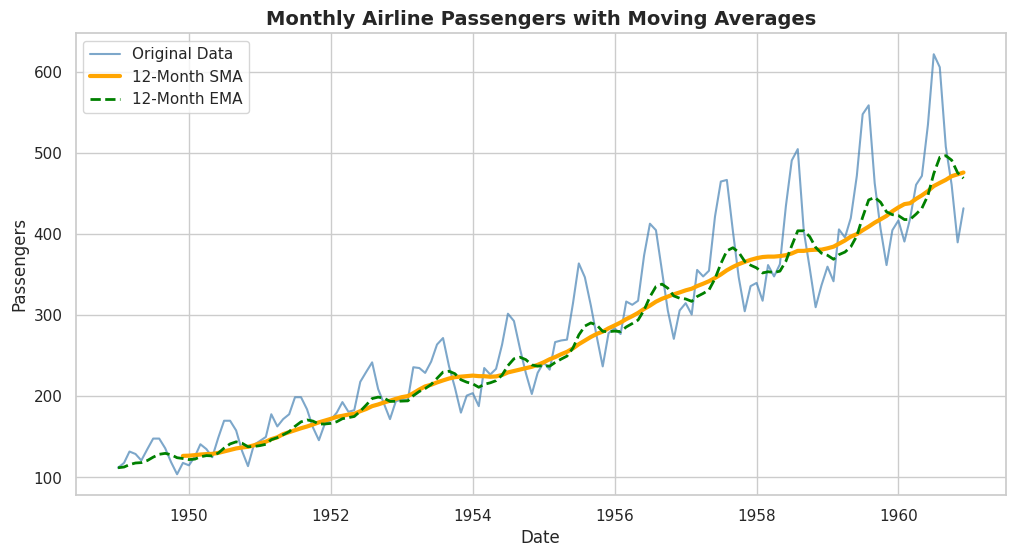

In [46]:
# Your Code
sma = ts.rolling(window=12).mean()
ema = ts.ewm(span=12, adjust=False).mean()

plt.figure(figsize=(12, 6))
plt.plot(ts, color='steelblue', alpha=0.7, linewidth=1.5, label='Original Data')
plt.plot(sma, color='orange', linewidth=3, label='12-Month SMA')
plt.plot(ema, color='green', linewidth=2, linestyle='--', label='12-Month EMA')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.title('Monthly Airline Passengers with Moving Averages', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.show()

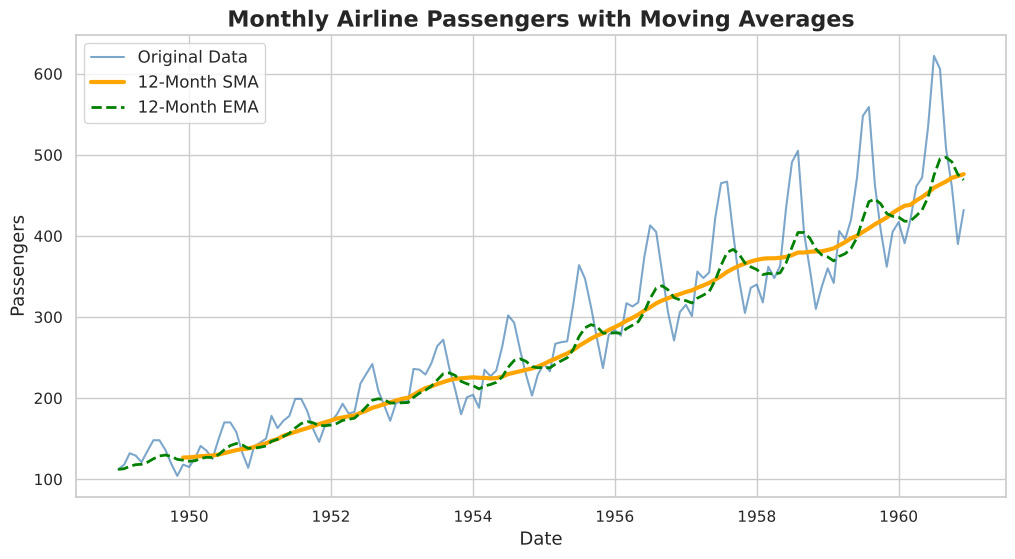

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The SMA needs 12 observations before it can compute its first average, so the first 11 months are empty (NaN) and the line starts in month 12. The EMA reacts faster because it gives more weight to recent values, while the SMA weights all 12 months equally.

### Exercise E2 — Bar Chart and Stacked Area Chart (2 points)
Create one figure with **two subplots** (1 × 2, `figsize=(16, 6)`):
- **Left:** a **bar chart** of the **total passengers per year**.
- **Right:** a **stacked area chart** of the **total passengers per quarter** (Q1–Q4) for each year, with a legend.

*Hint:* `ts.groupby([ts.index.year, ts.index.quarter]).sum().unstack()` gives a table with one row per year and one column per quarter.

Which quarter contributes the most passengers every year?

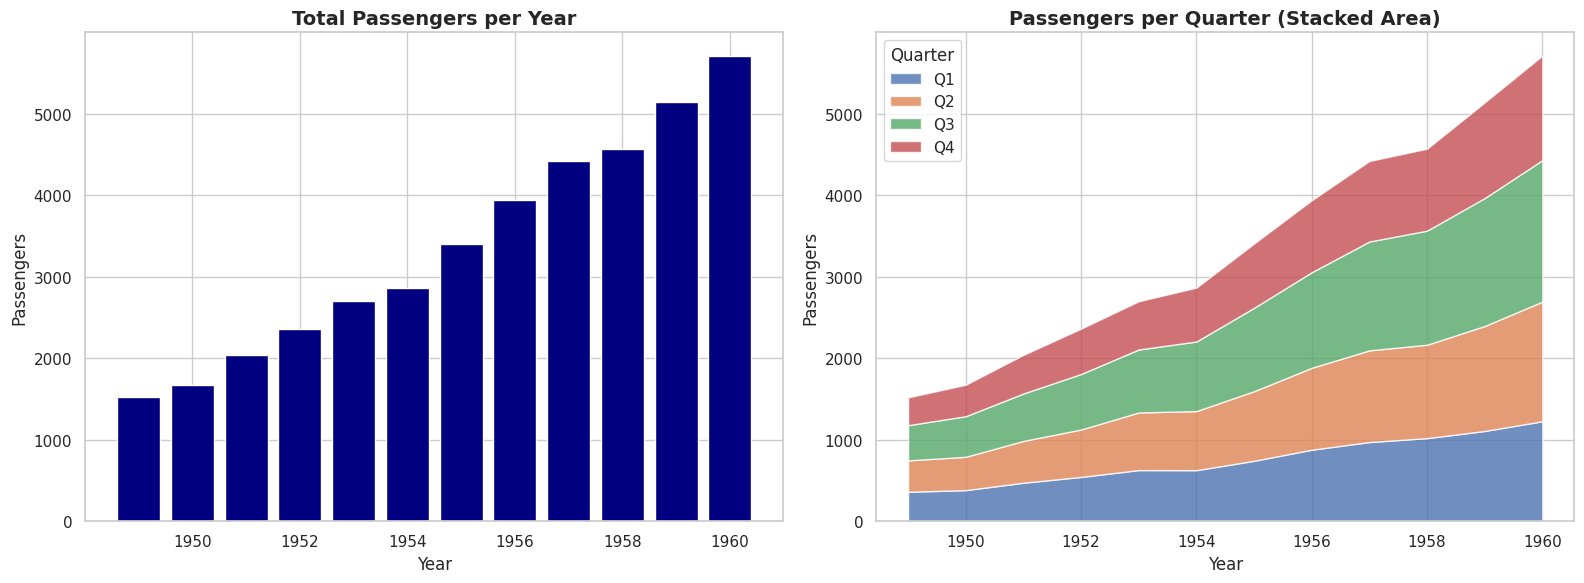

Q3    12
Name: count, dtype: int64


In [47]:
# Your Code
yearly = ts.groupby(ts.index.year).sum()
quarterly = ts.groupby([ts.index.year, ts.index.quarter]).sum().unstack()
quarterly.columns = ['Q1', 'Q2', 'Q3', 'Q4']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(yearly.index, yearly.values, color='navy')
axes[0].set_title('Total Passengers per Year', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Year', fontsize=12)
axes[0].set_ylabel('Passengers', fontsize=12)

axes[1].stackplot(quarterly.index, quarterly.T.values, labels=quarterly.columns, alpha=0.8)
axes[1].set_title('Passengers per Quarter (Stacked Area)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Year', fontsize=12)
axes[1].set_ylabel('Passengers', fontsize=12)
axes[1].legend(title='Quarter', loc='upper left')

plt.tight_layout()
plt.show()
print(quarterly.idxmax(axis=1).value_counts())

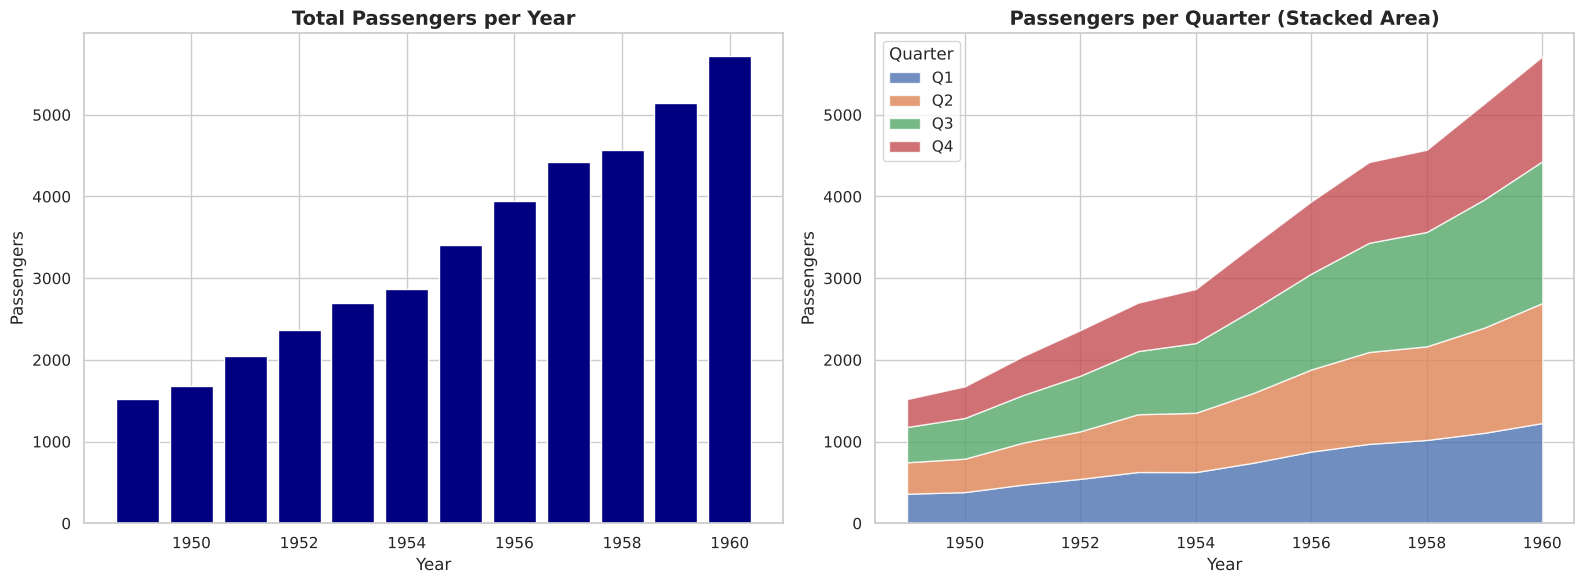

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: Q3 (July to September) contributes the most passengers in every year. I checked this: Q3 is the top quarter in all 12 years.

### Exercise E3 — Trend Analysis (2 points)
Fit two trend models to `ts`, using the month number `X = np.arange(len(ts)).reshape(-1, 1)` as the input:
1. A **linear trend** with `LinearRegression`
2. A **polynomial trend of degree 2** with `PolynomialFeatures` + `LinearRegression`

Plot the original series with both trend lines on the same axes and add a legend. Print the slope of the linear trend (passengers gained per month).

Linear trend slope: 2.66 passengers per month



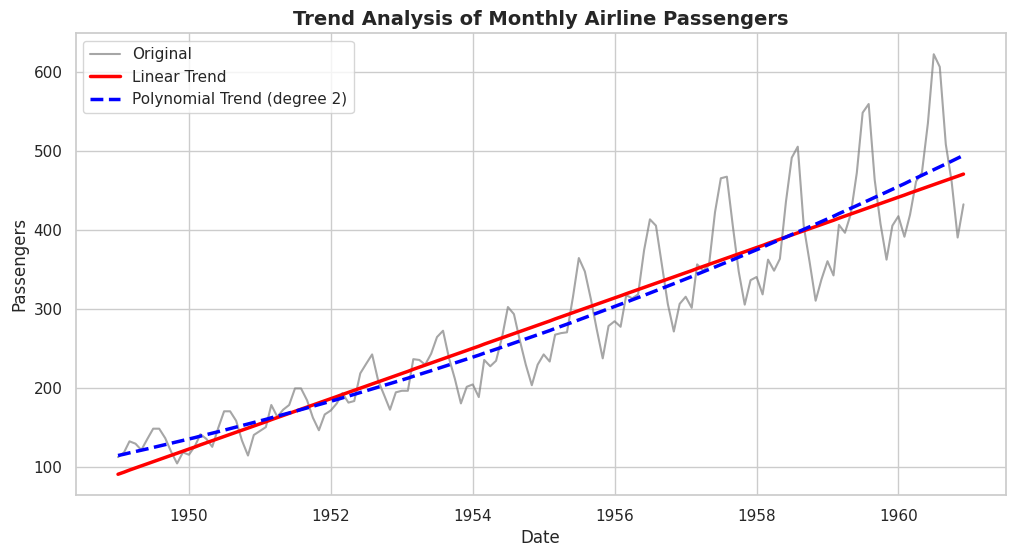

In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Your Code
X = np.arange(len(ts)).reshape(-1, 1)
y = ts.values

lin_model = LinearRegression().fit(X, y)
lin_trend = lin_model.predict(X)
print(f"Linear trend slope: {lin_model.coef_[0]:.2f} passengers per month")
print()

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
poly_model = LinearRegression().fit(X_poly, y)
poly_trend = poly_model.predict(X_poly)

plt.figure(figsize=(12, 6))
plt.plot(ts.index, y, color='gray', alpha=0.7, linewidth=1.5, label='Original')
plt.plot(ts.index, lin_trend, color='red', linewidth=2.5, label='Linear Trend')
plt.plot(ts.index, poly_trend, color='blue', linewidth=2.5, linestyle='--', label='Polynomial Trend (degree 2)')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.title('Trend Analysis of Monthly Airline Passengers', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.show()

Linear trend slope: 2.66 passengers per month


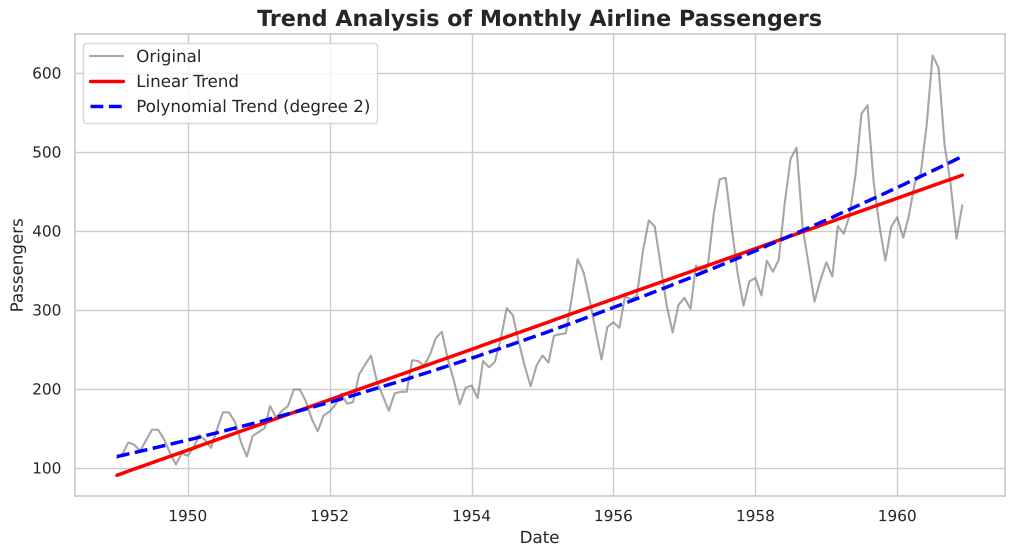

In [ ]:
# The output generated by the code written to answer this question should be as follows:

### Exercise E4 — Seasonal Decomposition (2 points)
Apply **STL decomposition** (`from statsmodels.tsa.seasonal import STL`) to `ts` with `seasonal=13` and plot the result (`result.plot()`). Set the figure size to `(12, 8)`.

Look at the **seasonal** component. Does the size of the seasonal swings stay constant or grow over time? Based on this, would an **additive** or a **multiplicative** model describe this series better?

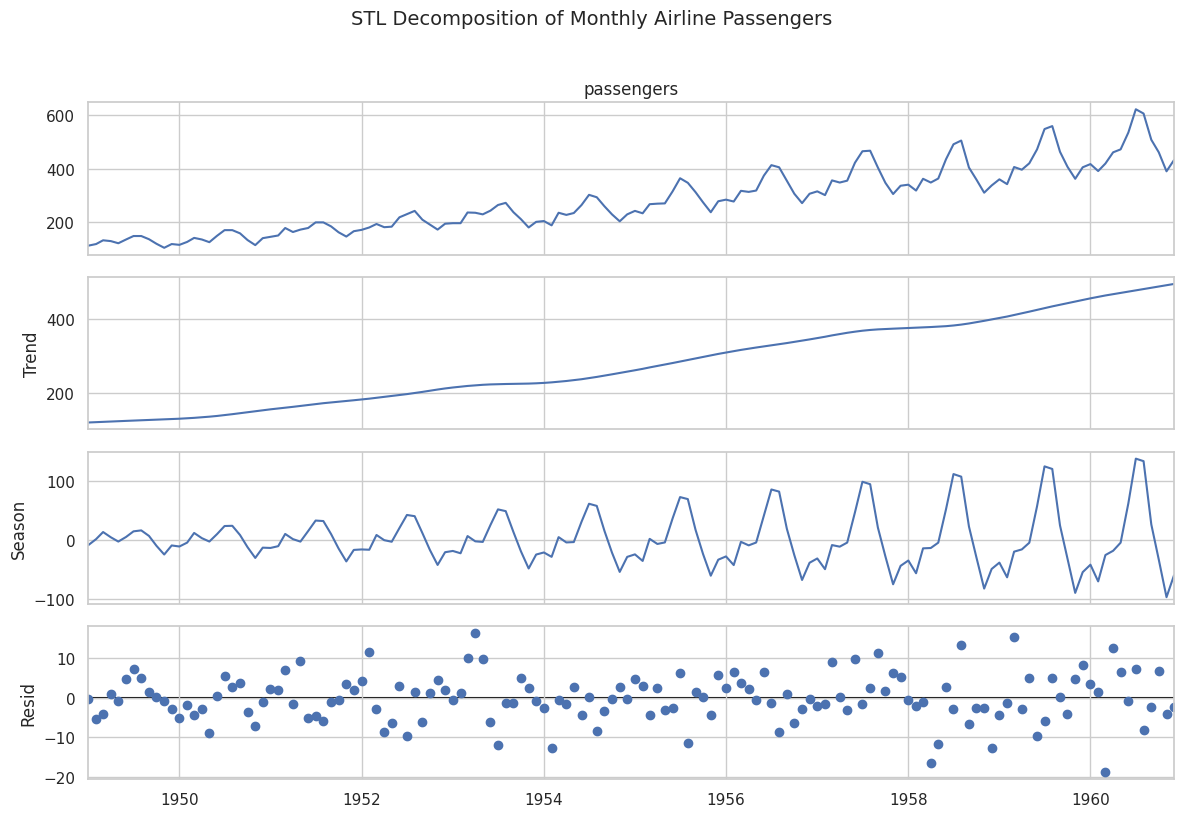

In [49]:
from statsmodels.tsa.seasonal import STL

# Your Code
result = STL(ts, seasonal=13).fit()
fig = result.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL Decomposition of Monthly Airline Passengers', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

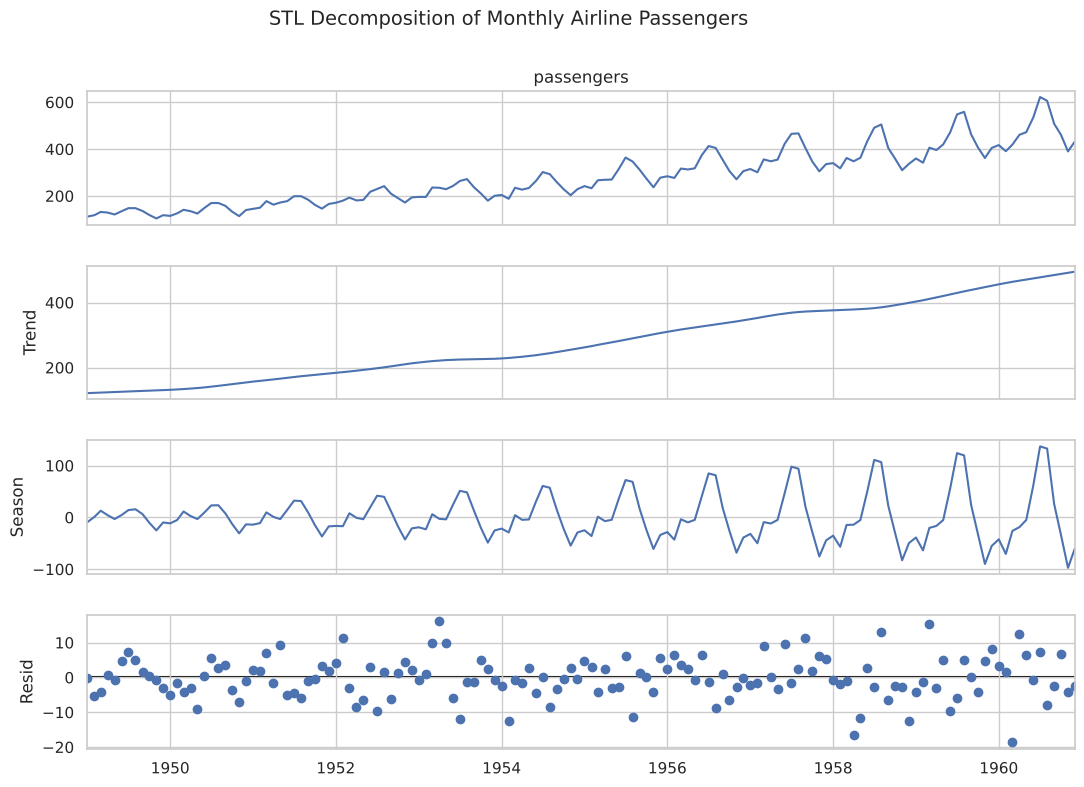

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The seasonal swings grow over time (from about ±20 in 1949 to about ±100 in 1960). Because the swings get bigger as the level rises, a multiplicative model describes this series better than an additive one.

### Exercise E5 — Stationarity and Differencing (2 points)
Use the **Augmented Dickey-Fuller test** (`from statsmodels.tsa.stattools import adfuller`) to check the stationarity of:
1. the original series `ts`
2. the **first difference** `ts.diff().dropna()`
3. the **first + seasonal (lag-12) difference** `ts.diff().diff(12).dropna()`

For each series, print the ADF statistic, the p-value and whether it is stationary at α = 0.05. Then plot the three series in a **3 × 1 subplot** grid (`figsize=(12, 10)`) with a title on each panel.

Original Series                    ADF =   0.815   p-value = 0.9919   -> Non-stationary
First Difference                   ADF =  -2.829   p-value = 0.0542   -> Non-stationary
First + Seasonal (12) Difference   ADF = -15.596   p-value = 0.0000   -> Stationary



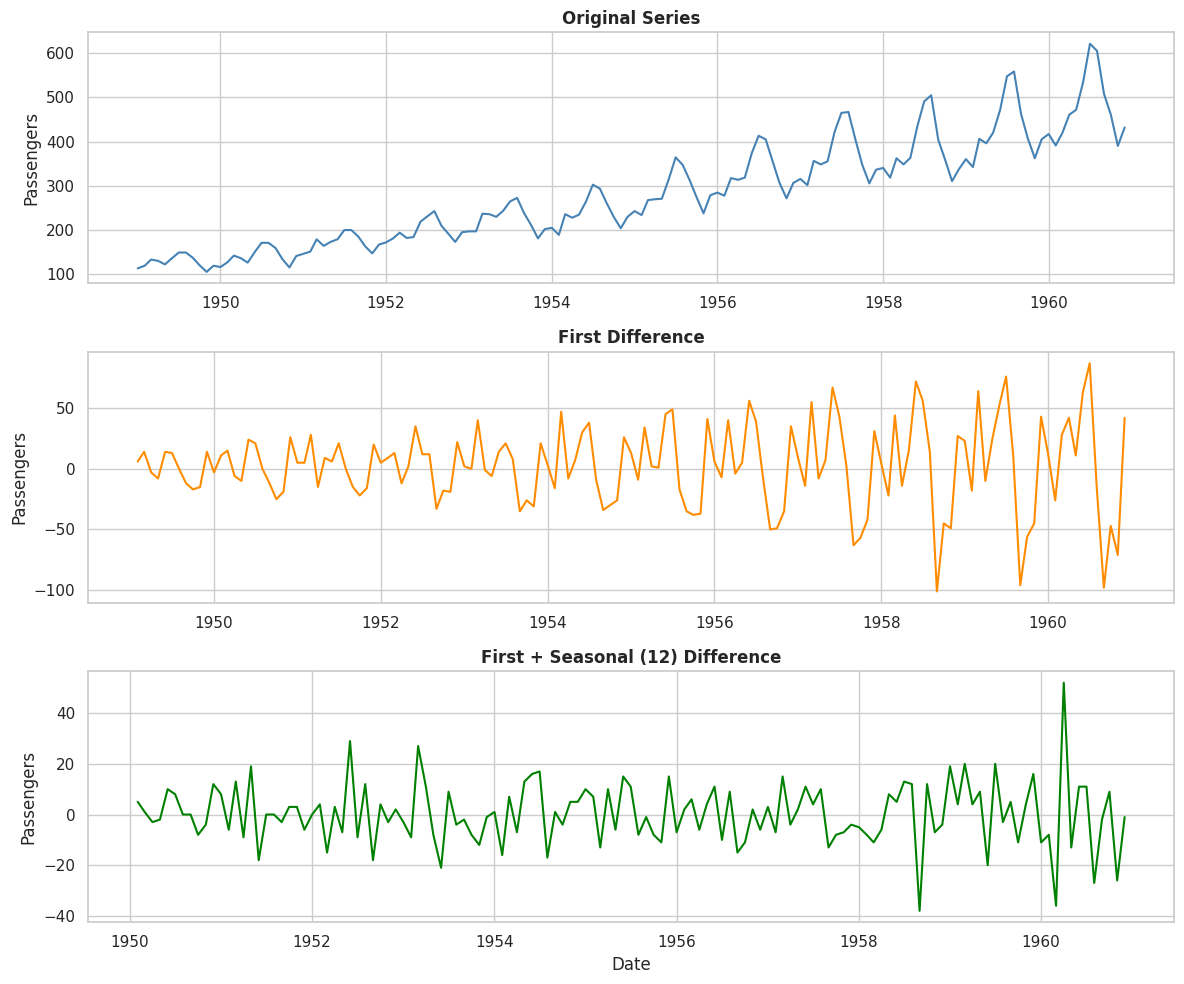

In [50]:
from statsmodels.tsa.stattools import adfuller

# Your Code
series_dict = {
    'Original Series': ts,
    'First Difference': ts.diff().dropna(),
    'First + Seasonal (12) Difference': ts.diff().diff(12).dropna()
}
for name, s in series_dict.items():
    stat, p = adfuller(s)[:2]
    verdict = 'Stationary' if p < 0.05 else 'Non-stationary'
    print(f"{name:<34} ADF = {stat:7.3f}   p-value = {p:.4f}   -> {verdict}")
print()

colors = ['steelblue', 'darkorange', 'green']
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (name, s), col in zip(axes, series_dict.items(), colors):
    ax.plot(s, color=col)
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Passengers')
axes[2].set_xlabel('Date')
plt.tight_layout()
plt.show()

Original Series                    ADF =   0.815   p-value = 0.9919   -> Non-stationary
First Difference                   ADF =  -2.829   p-value = 0.0542   -> Non-stationary
First + Seasonal (12) Difference   ADF = -15.596   p-value = 0.0000   -> Stationary


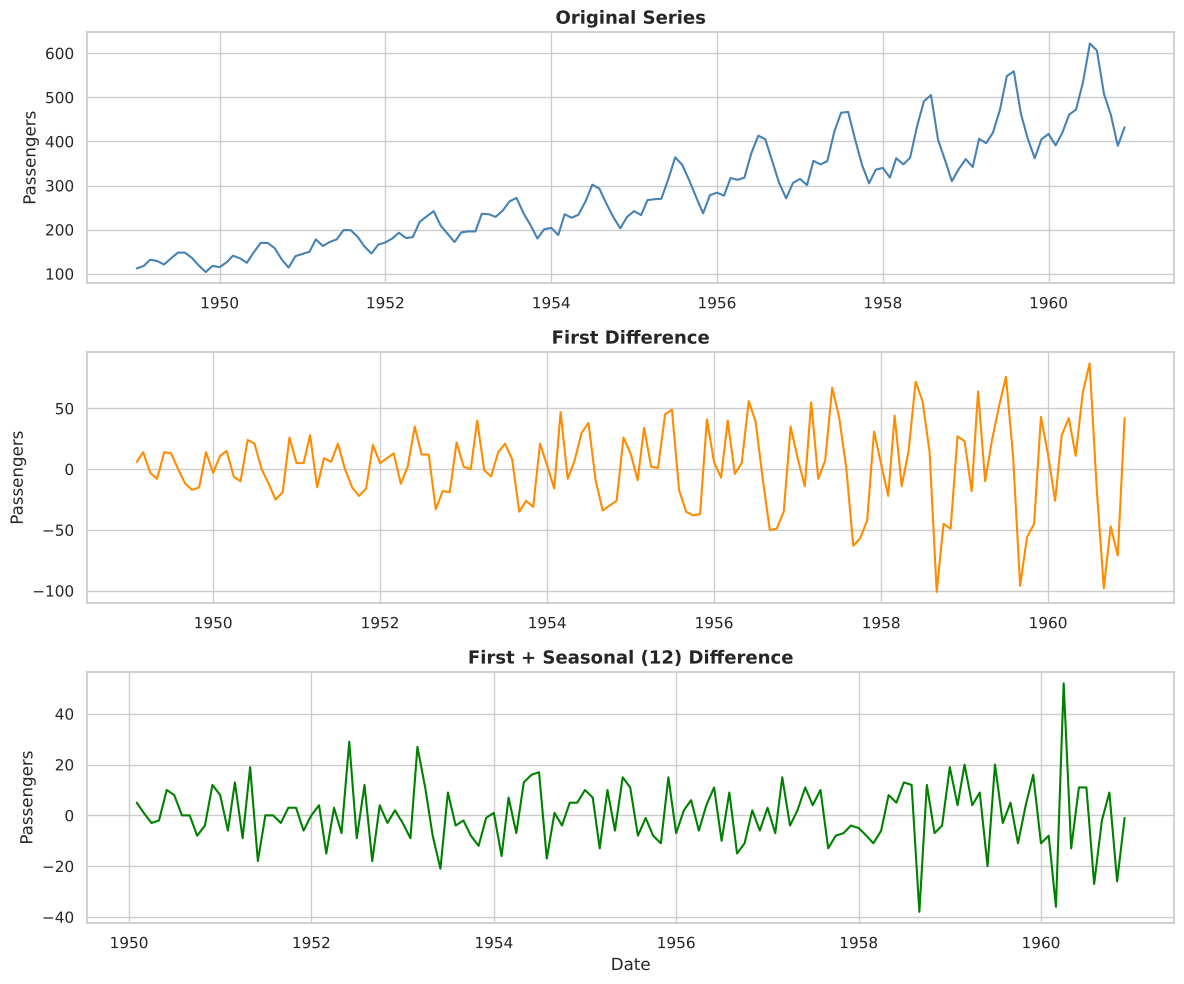

In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: The notebook has an answer cell after E5, but the exercise asks no question. In case you want something to write, the results show:

The original series is non-stationary (p = 0.9919).
The first difference is still non-stationary (p = 0.0542).
Only the first plus seasonal difference is stationary (p ≈ 0).

### Exercise E6 — Forecasting with ETS and ARIMA (3 points)
1. Split `ts` into a **training set** (1949–1958) and a **test set** (1959–1960): `train = ts[:'1958']`, `test = ts['1959':]`.
2. Fit an **Exponential Smoothing (ETS)** model (`from statsmodels.tsa.holtwinters import ExponentialSmoothing`) with `trend='add'`, `seasonal='mul'`, `seasonal_periods=12`, and forecast the next **24 months**.
3. Fit an **ARIMA(1, 1, 1)** model (`from statsmodels.tsa.arima.model import ARIMA`) and forecast the next 24 months, including the **95% confidence interval** (`get_forecast(...).conf_int()`).
4. Plot the training data, the actual test data, both forecasts, and the ARIMA confidence interval as a shaded band (`plt.fill_between`) on one figure (`figsize=(14, 7)`) with a legend.
5. Compute and print the **Mean Absolute Error (MAE)** of each model on the test set.

Which model forecasts better, and why?

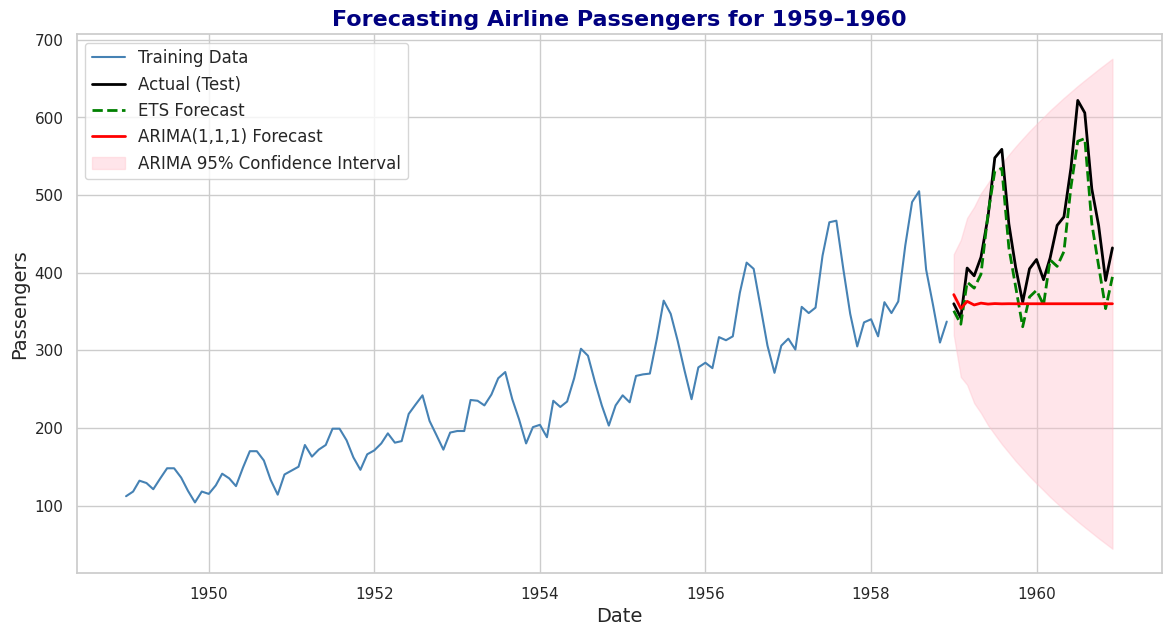

ETS   MAE: 28.98
ARIMA MAE: 93.90


In [51]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

# Your Code
train = ts[:'1958']
test = ts['1959':]

ets_model = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12).fit()
ets_fc = ets_model.forecast(24)

arima_model = ARIMA(train, order=(1, 1, 1)).fit()
arima_res = arima_model.get_forecast(steps=24)
arima_fc = arima_res.predicted_mean
conf = arima_res.conf_int()

plt.figure(figsize=(14, 7))
plt.plot(train, color='steelblue', label='Training Data')
plt.plot(test, color='black', linewidth=2, label='Actual (Test)')
plt.plot(ets_fc, color='green', linewidth=2, linestyle='--', label='ETS Forecast')
plt.plot(arima_fc, color='red', linewidth=2, label='ARIMA(1,1,1) Forecast')
plt.fill_between(conf.index, conf.iloc[:, 0], conf.iloc[:, 1],
                 color='pink', alpha=0.4, label='ARIMA 95% Confidence Interval')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Passengers', fontsize=14)
plt.title('Forecasting Airline Passengers for 1959\u20131960', fontsize=16, fontweight='bold', color='navy')
plt.legend(fontsize=12)
plt.show()

from sklearn.metrics import mean_absolute_error
print(f"ETS   MAE: {mean_absolute_error(test, ets_fc):.2f}")
print(f"ARIMA MAE: {mean_absolute_error(test, arima_fc):.2f}")

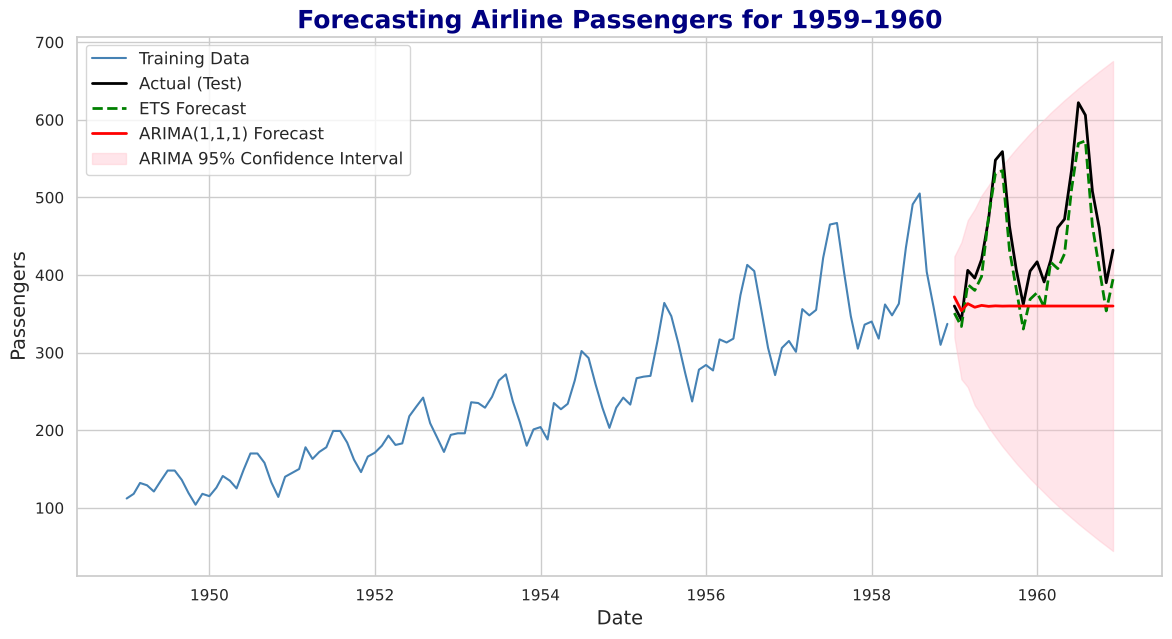

ETS   MAE: 28.98
ARIMA MAE: 93.90


In [ ]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here: ETS forecasts better (MAE 28.98 vs 93.90). It models both the upward trend and the multiplicative seasonality, so its forecast follows the yearly peaks and dips. ARIMA(1,1,1) has no seasonal component, so its forecast flattens into a nearly straight line. Its 95% interval is also very wide, which shows how uncertain it is.

---
## End of Assignment